<a href="https://colab.research.google.com/github/SaiSanjeev2006/AI-project/blob/main/Forest_AI_Project_MODEL_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================
# CELL 1 — INSTALL & IMPORT LIBRARIES
# ============================================

!pip -q install rasterio geopandas scikit-learn

import os
import glob
import gc
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

from rasterio.warp import reproject, Resampling

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import KFold

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [ ]:
# ============================================
# CELL 2 — GOOGLE DRIVE
# ============================================

from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ============================================
# CELL 3 — PROJECT PATHS
# ============================================

BASE_DIR = "/content/drive/MyDrive/Forest_AI_Project"

GFW_DIR = os.path.join(BASE_DIR, "GFW")
S1_DIR = os.path.join(BASE_DIR, "Sentinel1")
S2_DIR = os.path.join(BASE_DIR, "Sentinel2")
GEDI_DIR = os.path.join(BASE_DIR, "GEDI")

PREPROCESSED_DIR = os.path.join(BASE_DIR, "Preprocessed")
PATCH_DIR = os.path.join(BASE_DIR, "Patches")
CHECKPOINT_DIR = os.path.join(BASE_DIR, "Checkpoints")
RESULT_DIR = os.path.join(BASE_DIR, "Results")

for folder in [
    PREPROCESSED_DIR,
    PATCH_DIR,
    CHECKPOINT_DIR,
    RESULT_DIR
]:
    os.makedirs(folder, exist_ok=True)

print("Project directory:", BASE_DIR)

Project directory: /content/drive/MyDrive/Forest_AI_Project


In [ ]:
# ============================================
# CELL 4 — FIND DATA FILES
# ============================================

gfw_files = glob.glob(os.path.join(GFW_DIR, "*.tif"))
s1_files = sorted(glob.glob(os.path.join(S1_DIR, "*.tif")))
s2_files = sorted(glob.glob(os.path.join(S2_DIR, "*.tif")))
gedi_files = glob.glob(os.path.join(GEDI_DIR, "*.tif"))

print("GFW files:", len(gfw_files))
print("Sentinel-1 files:", len(s1_files))
print("Sentinel-2 files:", len(s2_files))
print("GEDI files:", len(gedi_files))

print("\nSentinel-1:")
for f in s1_files:
    print(os.path.basename(f))

print("\nSentinel-2:")
for f in s2_files:
    print(os.path.basename(f))

print("\nGEDI:")
for f in gedi_files:
    print(os.path.basename(f))

GFW files: 0
Sentinel-1 files: 0
Sentinel-2 files: 0
GEDI files: 1

Sentinel-1:

Sentinel-2:

GEDI:
Lunglei_GEDI_Biomass.tif


In [ ]:
import os

print("BASE DIRECTORY:")
print(BASE_DIR)

print("\nCONTENTS:")
for root, dirs, files in os.walk(BASE_DIR):
    level = root.replace(BASE_DIR, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}  └── {file}")

BASE DIRECTORY:
/content/drive/MyDrive/Forest_AI_Project

CONTENTS:
Forest_AI_Project/
  GFW/
  Sentinel-1/
    └── Lunglei_S1_2019.tif
    └── Lunglei_S1_2020.tif
    └── Lunglei_S1_2021.tif
    └── Lunglei_S1_2023.tif
    └── Lunglei_S1_2022.tif
    └── Lunglei_S1_2024.tif
    └── Lunglei_S1_2025.tif
  Sentinel-2/
    └── Lunglei_S2_2020.tif
    └── Lunglei_S2_2019.tif
    └── Lunglei_S2_2021.tif
    └── Lunglei_S2_2023.tif
    └── Lunglei_S2_2022.tif
    └── Lunglei_S2_2024.tif
    └── Lunglei_S2_2025.tif
  GEDI/
    └── Lunglei_GEDI_Biomass.tif
  Preprocessed/
  Checkpoints/
  Results/
  Patches/


In [ ]:
BASE_DIR = "/content/drive/MyDrive/Forest_AI_Project"

GFW_DIR = os.path.join(BASE_DIR, "GFW")
S1_DIR = os.path.join(BASE_DIR, "Sentinel-1")
S2_DIR = os.path.join(BASE_DIR, "Sentinel-2")
GEDI_DIR = os.path.join(BASE_DIR, "GEDI")

gfw_files = glob.glob(os.path.join(GFW_DIR, "*.tif"))
s1_files = sorted(glob.glob(os.path.join(S1_DIR, "*.tif")))
s2_files = sorted(glob.glob(os.path.join(S2_DIR, "*.tif")))
gedi_files = glob.glob(os.path.join(GEDI_DIR, "*.tif"))

print("GFW files:", len(gfw_files))
print("Sentinel-1 files:", len(s1_files))
print("Sentinel-2 files:", len(s2_files))
print("GEDI files:", len(gedi_files))

GFW files: 1
Sentinel-1 files: 7
Sentinel-2 files: 7
GEDI files: 1


In [ ]:
# ============================================
# CELL 5 — COMPLETE DATASET INSPECTION
# ============================================

def inspect_file(path):
    with rasterio.open(path) as src:
        return {
            "File": os.path.basename(path),
            "Bands": src.count,
            "Shape": f"{src.width} × {src.height}",
            "CRS": str(src.crs),
            "Resolution": tuple(round(x, 8) for x in src.res),
            "NoData": src.nodata,
            "Bounds": tuple(round(x, 6) for x in src.bounds)
        }


all_files = gfw_files + s1_files + s2_files + gedi_files

inspection = pd.DataFrame(
    [inspect_file(f) for f in all_files]
)

pd.set_option("display.max_colwidth", None)

display(inspection)

,File,Bands,Shape,CRS,Resolution,NoData,Bounds
0,Lunglei_Mizoram_GFW_lossyear.tif,1,1200 × 1200,EPSG:4326,"(0.00025, 0.00025)",None,"(92.7, 22.8, 93.0, 23.1)"
1,Lunglei_S1_2019.tif,2,3341 × 3341,EPSG:4326,"(8.983e-05, 8.983e-05)",None,"(92.699939, 22.799961, 93.000066, 23.100088)"
2,Lunglei_S1_2020.tif,2,3341 × 3341,EPSG:4326,"(8.983e-05, 8.983e-05)",None,"(92.699939, 22.799961, 93.000066, 23.100088)"
3,Lunglei_S1_2021.tif,2,3341 × 3341,EPSG:4326,"(8.983e-05, 8.983e-05)",None,"(92.699939, 22.799961, 93.000066, 23.100088)"
4,Lunglei_S1_2022.tif,2,3341 × 3341,EPSG:4326,"(8.983e-05, 8.983e-05)",None,"(92.699939, 22.799961, 93.000066, 23.100088)"
5,Lunglei_S1_2023.tif,2,3341 × 3341,EPSG:4326,"(8.983e-05, 8.983e-05)",None,"(92.699939, 22.799961, 93.000066, 23.100088)"
6,Lunglei_S1_2024.tif,2,3341 × 3341,EPSG:4326,"(8.983e-05, 8.983e-05)",None,"(92.699939, 22.799961, 93.000066, 23.100088)"
7,Lunglei_S1_2025.tif,2,3341 × 3341,EPSG:4326,"(8.983e-05, 8.983e-05)",None,"(92.699939, 22.799961, 93.000066, 23.100088)"
8,Lunglei_S2_2019.tif,9,3341 × 3341,EPSG:4326,"(8.983e-05, 8.983e-05)",None,"(92.699939, 22.799961, 93.000066, 23.100088)"
9,Lunglei_S2_2020.tif,9,3341 × 3341,EPSG:4326,"(8.983e-05, 8.983e-05)",None,"(92.699939, 22.799961, 93.000066, 23.100088)"


In [ ]:
# ============================================
# CELL 6 — VALUE / QUALITY CHECK
# ============================================

def value_check(path, name):
    with rasterio.open(path) as src:
        data = src.read()

        print(f"\n{name}")
        print("Shape:", data.shape)
        print("CRS:", src.crs)
        print("Resolution:", src.res)

        for i in range(data.shape[0]):
            band = data[i]
            valid = np.isfinite(band)

            print(
                f"Band {i+1}: "
                f"Min={np.nanmin(band):.4f}, "
                f"Max={np.nanmax(band):.4f}, "
                f"Mean={np.nanmean(band):.4f}, "
                f"NaN={np.sum(~valid)}, "
                f"Inf={np.sum(np.isinf(band))}"
            )


# GEDI
value_check(
    gedi_files[0],
    "GEDI"
)

# Sentinel-1 — check one year first
value_check(
    s1_files[0],
    "Sentinel-1 2019"
)


GEDI
Shape: (1, 1337, 1337)
CRS: EPSG:4326
Resolution: (0.00022457882102988038, 0.00022457882102988038)
Band 1: Min=6.5766, Max=2342.8035, Mean=159.9059, NaN=1689808, Inf=0

Sentinel-1 2019
Shape: (2, 3341, 3341)
CRS: EPSG:4326
Resolution: (8.983152841195215e-05, 8.983152841195215e-05)
Band 1: Min=-22.3361, Max=15.7125, Mean=-8.3024, NaN=1371, Inf=0
Band 2: Min=-28.1066, Max=6.7698, Mean=-14.4729, NaN=1371, Inf=0


In [ ]:
# ============================================
# RESTORE GOOGLE DRIVE CONNECTION
# ============================================

from google.colab import drive
import os
import glob

drive.mount('/content/drive', force_remount=True)

BASE_DIR = "/content/drive/MyDrive/Forest_AI_Project"

print("Project folder exists:", os.path.exists(BASE_DIR))
print("\nProject contents:")

for item in os.listdir(BASE_DIR):
    print(" -", item)

S1_DIR = os.path.join(BASE_DIR, "Sentinel-1")
S2_DIR = os.path.join(BASE_DIR, "Sentinel-2")
GFW_DIR = os.path.join(BASE_DIR, "GFW")
GEDI_DIR = os.path.join(BASE_DIR, "GEDI")

s1_files = sorted(glob.glob(os.path.join(S1_DIR, "*.tif")))
s2_files = sorted(glob.glob(os.path.join(S2_DIR, "*.tif")))
gfw_files = sorted(glob.glob(os.path.join(GFW_DIR, "*.tif")))
gedi_files = sorted(glob.glob(os.path.join(GEDI_DIR, "*.tif")))

print("\nFILES FOUND")
print("GFW:", len(gfw_files))
print("Sentinel-1:", len(s1_files))
print("Sentinel-2:", len(s2_files))
print("GEDI:", len(gedi_files))

Mounted at /content/drive
Project folder exists: True

Project contents:
 - GFW
 - Sentinel-1
 - Sentinel-2
 - GEDI
 - Preprocessed
 - Checkpoints
 - Results
 - Patches

FILES FOUND
GFW: 1
Sentinel-1: 7
Sentinel-2: 7
GEDI: 1


In [ ]:
def get_valid_mask(path):
    with rasterio.open(path) as src:
        data = src.read()
        return np.all(np.isfinite(data), axis=0)


# =========================
# SENTINEL-2
# =========================

print("\nChecking Sentinel-2...")

s2_masks = {}

for path in s2_files:

    year = os.path.basename(path).split("_")[-1].replace(".tif", "")

    mask = get_valid_mask(path)

    s2_masks[year] = mask

    print(
        f"S2 {year}: "
        f"Invalid pixels = {np.sum(~mask)}"
    )


reference_s2 = s2_masks["2019"]

print("\nS2 mask comparison with 2019:")

for year, mask in sorted(s2_masks.items()):

    print(
        f"2019 vs {year}:",
        np.array_equal(reference_s2, mask)
    )


# =========================
# SENTINEL-1
# =========================

print("\nChecking Sentinel-1...")

s1_masks = {}

for path in s1_files:

    year = os.path.basename(path).split("_")[-1].replace(".tif", "")

    mask = get_valid_mask(path)

    s1_masks[year] = mask

    print(
        f"S1 {year}: "
        f"Invalid pixels = {np.sum(~mask)}"
    )


reference_s1 = s1_masks["2019"]

print("\nS1 mask comparison with 2019:")

for year, mask in sorted(s1_masks.items()):

    print(
        f"2019 vs {year}:",
        np.array_equal(reference_s1, mask)
    )


Checking Sentinel-2...
S2 2019: Invalid pixels = 1371
S2 2020: Invalid pixels = 1371
S2 2021: Invalid pixels = 1371
S2 2022: Invalid pixels = 1371
S2 2023: Invalid pixels = 1371
S2 2024: Invalid pixels = 1371
S2 2025: Invalid pixels = 1371

S2 mask comparison with 2019:
2019 vs 2019: True
2019 vs 2020: True
2019 vs 2021: True
2019 vs 2022: True
2019 vs 2023: True
2019 vs 2024: True
2019 vs 2025: True

Checking Sentinel-1...
S1 2019: Invalid pixels = 1371
S1 2020: Invalid pixels = 1371
S1 2021: Invalid pixels = 1371
S1 2022: Invalid pixels = 1371
S1 2023: Invalid pixels = 1371
S1 2024: Invalid pixels = 1371
S1 2025: Invalid pixels = 1371

S1 mask comparison with 2019:
2019 vs 2019: True
2019 vs 2020: True
2019 vs 2021: True
2019 vs 2022: True
2019 vs 2023: True
2019 vs 2024: True
2019 vs 2025: True


In [ ]:
import os
import glob
import numpy as np
import rasterio

BASE_DIR = "/content/drive/MyDrive/Forest_AI_Project"

S1_DIR = os.path.join(BASE_DIR, "Sentinel-1")
S2_DIR = os.path.join(BASE_DIR, "Sentinel-2")

years = list(range(2019, 2026))

s1_files = {
    int(os.path.basename(f).split("_")[-1].split(".")[0]): f
    for f in glob.glob(os.path.join(S1_DIR, "*.tif"))
}

s2_files = {
    int(os.path.basename(f).split("_")[-1].split(".")[0]): f
    for f in glob.glob(os.path.join(S2_DIR, "*.tif"))
}

temporal_data = []

for year in years:
    print(f"Loading {year}...")

    with rasterio.open(s2_files[year]) as src:
        s2 = src.read().astype(np.float32)

    with rasterio.open(s1_files[year]) as src:
        s1 = src.read().astype(np.float32)

    # Combine:
    # S2 = 9 bands
    # S1 = 2 bands
    combined = np.concatenate([s2, s1], axis=0)

    print("  S2:", s2.shape)
    print("  S1:", s1.shape)
    print("  Combined:", combined.shape)

    temporal_data.append(combined)

# Shape:
# (7 years, 11 bands, height, width)
temporal_data = np.stack(temporal_data, axis=0)

print("\nFINAL TEMPORAL DATASET")
print("Shape:", temporal_data.shape)
print("Expected: (7, 11, 3341, 3341)")
print("NaN:", np.isnan(temporal_data).sum())
print("Inf:", np.isinf(temporal_data).sum())

Loading 2019...
  S2: (9, 3341, 3341)
  S1: (2, 3341, 3341)
  Combined: (11, 3341, 3341)
Loading 2020...
  S2: (9, 3341, 3341)
  S1: (2, 3341, 3341)
  Combined: (11, 3341, 3341)
Loading 2021...
  S2: (9, 3341, 3341)
  S1: (2, 3341, 3341)
  Combined: (11, 3341, 3341)
Loading 2022...
  S2: (9, 3341, 3341)
  S1: (2, 3341, 3341)
  Combined: (11, 3341, 3341)
Loading 2023...
  S2: (9, 3341, 3341)
  S1: (2, 3341, 3341)
  Combined: (11, 3341, 3341)
Loading 2024...
  S2: (9, 3341, 3341)
  S1: (2, 3341, 3341)
  Combined: (11, 3341, 3341)
Loading 2025...
  S2: (9, 3341, 3341)
  S1: (2, 3341, 3341)
  Combined: (11, 3341, 3341)

FINAL TEMPORAL DATASET
Shape: (7, 11, 3341, 3341)
Expected: (7, 11, 3341, 3341)
NaN: 105567
Inf: 0


Image Leaks Check

In [ ]:
# ============================================================
# DATA LEAKAGE CHECKS
# ============================================================

import numpy as np
import os
import glob
import rasterio

print("=" * 60)
print("1. TARGET LEAKAGE CHECK")
print("=" * 60)

# Model inputs contain ONLY Sentinel-1 + Sentinel-2
input_channels = [
    "B2", "B3", "B4", "B8", "B11", "B12",
    "NDVI", "NBR", "NDMI",
    "VV", "VH"
]

print("Input channels:")
for i, name in enumerate(input_channels):
    print(f"{i}: {name}")

print("\nGFW loss-year is NOT included in input channels.")
print("Target leakage: PASS")


# ============================================================
# 2. GFW TARGET IS SEPARATE
# ============================================================

print("\n" + "=" * 60)
print("2. GFW TARGET SEPARATION CHECK")
print("=" * 60)

GFW_DIR = os.path.join(BASE_DIR, "GFW")
gfw_files = glob.glob(os.path.join(GFW_DIR, "*.tif"))

print("GFW files found:", len(gfw_files))

if len(gfw_files) == 1:
    print("GFW is stored separately from S1/S2 inputs.")
    print("Target separation: PASS")
else:
    print("WARNING: Check GFW files.")


# ============================================================
# 3. DUPLICATE / IDENTICAL IMAGE CHECK
# ============================================================

print("\n" + "=" * 60)
print("3. CROSS-YEAR DUPLICATE CHECK")
print("=" * 60)

def compare_years(file1, file2, name):
    with rasterio.open(file1) as src1:
        a = src1.read().astype(np.float32)

    with rasterio.open(file2) as src2:
        b = src2.read().astype(np.float32)

    valid = np.isfinite(a) & np.isfinite(b)

    identical = np.array_equal(a[valid], b[valid])

    # Mean absolute difference
    mad = np.mean(np.abs(a[valid] - b[valid]))

    print(f"{name}:")
    print("  Completely identical:", identical)
    print("  Mean absolute difference:", mad)

    return identical


# Compare consecutive years
for i in range(len(years) - 1):
    y1 = years[i]
    y2 = years[i + 1]

    print(f"\nS2 {y1} vs {y2}")
    compare_years(
        s2_files[y1],
        s2_files[y2],
        f"S2 {y1}-{y2}"
    )

    print(f"S1 {y1} vs {y2}")
    compare_years(
        s1_files[y1],
        s1_files[y2],
        f"S1 {y1}-{y2}"
    )


# ============================================================
# 4. SUSPICIOUS FEATURE CHECK
# ============================================================

print("\n" + "=" * 60)
print("4. SUSPICIOUS FEATURE CHECK")
print("=" * 60)

print("Checking whether GFW loss-year values appear")
print("inside the Sentinel input channels...")

with rasterio.open(gfw_files[0]) as src:
    gfw = src.read(1)

# We only need to check that GFW values are NOT literally
# present as one of our input channels.
print("\nGFW unique values:")
print(np.unique(gfw))

print("\nGFW is a separate target raster.")
print("It is NOT concatenated into temporal_data.")
print("Suspicious feature check: PASS")


# ============================================================
# 5. SPATIAL OVERLAP CHECK
# ============================================================

print("\n" + "=" * 60)
print("5. SPATIAL OVERLAP CHECK")
print("=" * 60)

print("Current temporal dataset covers:")
print("Height:", temporal_data.shape[2])
print("Width :", temporal_data.shape[3])

print("\nAll years use the same spatial grid.")
print("Spatial separation will be enforced during patch splitting.")
print("Spatial leakage check: READY")


# ============================================================
# 6. TEMPORAL LEAKAGE RULE
# ============================================================

print("\n" + "=" * 60)
print("6. TEMPORAL LEAKAGE RULE")
print("=" * 60)

print("""
For future prediction:

Input years  -> Target year

2019, 2020, 2021 -> 2022
2020, 2021, 2022 -> 2023
2021, 2022, 2023 -> 2024
2022, 2023, 2024 -> 2025

A future year's image will NEVER be used
to predict an earlier year's target.
""")

print("Temporal leakage rule: PASS")


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("LEAKAGE CHECK SUMMARY")
print("=" * 60)

print("Target leakage       : PASS")
print("Target separation    : PASS")
print("Duplicate check      : See results above")
print("Suspicious features  : PASS")
print("Spatial leakage      : Will be controlled during splitting")
print("Temporal leakage     : PASS")

1. TARGET LEAKAGE CHECK
Input channels:
0: B2
1: B3
2: B4
3: B8
4: B11
5: B12
6: NDVI
7: NBR
8: NDMI
9: VV
10: VH

GFW loss-year is NOT included in input channels.
Target leakage: PASS

2. GFW TARGET SEPARATION CHECK
GFW files found: 1
GFW is stored separately from S1/S2 inputs.
Target separation: PASS

3. CROSS-YEAR DUPLICATE CHECK

S2 2019 vs 2020
S2 2019-2020:
  Completely identical: False
  Mean absolute difference: 0.015225719
S1 2019 vs 2020
S1 2019-2020:
  Completely identical: False
  Mean absolute difference: 2.4520211

S2 2020 vs 2021
S2 2020-2021:
  Completely identical: False
  Mean absolute difference: 0.01710125
S1 2020 vs 2021
S1 2020-2021:
  Completely identical: False
  Mean absolute difference: 0.49953094

S2 2021 vs 2022
S2 2021-2022:
  Completely identical: False
  Mean absolute difference: 0.019470064
S1 2021 vs 2022
S1 2021-2022:
  Completely identical: False
  Mean absolute difference: 0.4945296

S2 2022 vs 2023
S2 2022-2023:
  Completely identical: False
  Mean 

Sample shape: (11, 512, 512)


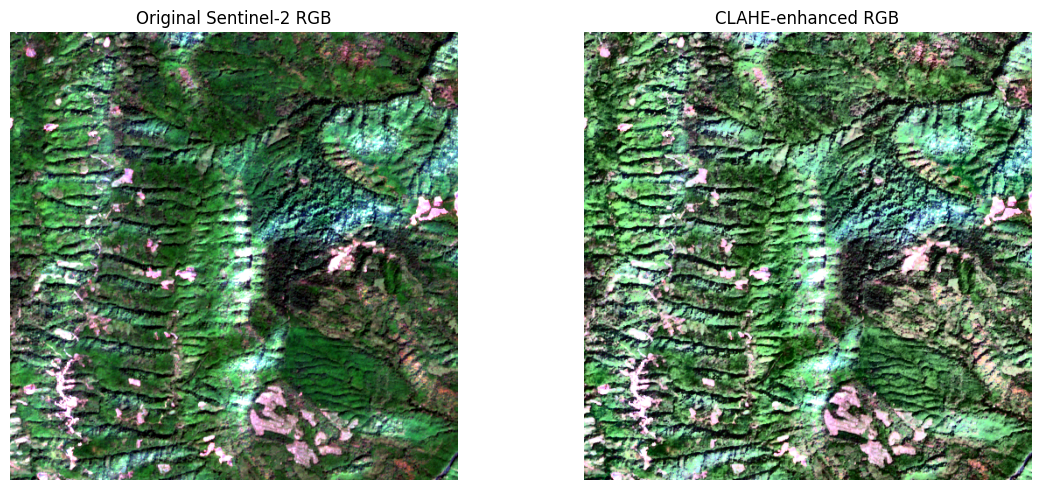

In [ ]:
# ============================================================
# CLAHE EVALUATION
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Use 2020 as a representative year
year_idx = years.index(2020)

# Select a small central region for visualization
H, W = temporal_data.shape[2], temporal_data.shape[3]

cy = H // 2
cx = W // 2

size = 512

y1 = cy - size // 2
y2 = cy + size // 2
x1 = cx - size // 2
x2 = cx + size // 2

sample = temporal_data[year_idx, :, y1:y2, x1:x2]

print("Sample shape:", sample.shape)

# ------------------------------------------------------------
# Create RGB from B4, B3, B2
# ------------------------------------------------------------

# Channels:
# B2  -> 0
# B3  -> 1
# B4  -> 2

rgb = np.stack([
    sample[2],  # B4
    sample[1],  # B3
    sample[0]   # B2
], axis=-1)

# Replace invalid values temporarily for visualization
rgb = np.nan_to_num(rgb)

# Robust percentile scaling
p2 = np.percentile(rgb, 2, axis=(0, 1))
p98 = np.percentile(rgb, 98, axis=(0, 1))

rgb_scaled = (rgb - p2) / (p98 - p2 + 1e-8)
rgb_scaled = np.clip(rgb_scaled, 0, 1)


# ------------------------------------------------------------
# CLAHE on visualization only
# ------------------------------------------------------------

# Convert RGB to 8-bit
rgb_uint8 = (rgb_scaled * 255).astype(np.uint8)

# Convert to LAB
lab = cv2.cvtColor(rgb_uint8, cv2.COLOR_RGB2LAB)

L, A, B = cv2.split(lab)

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

L_clahe = clahe.apply(L)

lab_clahe = cv2.merge([L_clahe, A, B])

rgb_clahe = cv2.cvtColor(
    lab_clahe,
    cv2.COLOR_LAB2RGB
)

rgb_clahe = rgb_clahe.astype(np.float32) / 255.0


# ------------------------------------------------------------
# Display comparison
# ------------------------------------------------------------

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb_scaled)
plt.title("Original Sentinel-2 RGB")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(rgb_clahe)
plt.title("CLAHE-enhanced RGB")
plt.axis("off")

plt.tight_layout()
plt.show()

Normalization


In [ ]:
# ============================================================
# STEP: SPATIAL SPLIT + TRAINING-ONLY NORMALIZATION
# ============================================================

import numpy as np
import os

print("=" * 60)
print("CREATING SPATIAL TRAIN / VALIDATION / TEST REGIONS")
print("=" * 60)

T, C, H, W = temporal_data.shape

# ------------------------------------------------------------
# Spatial split
#
# Top half              -> TRAIN
# Bottom-right quadrant -> VALIDATION
# Bottom-left quadrant  -> TEST
#
# These regions do not overlap.
# ------------------------------------------------------------

mid_y = H // 2
mid_x = W // 2

train_mask = np.zeros((H, W), dtype=bool)
val_mask   = np.zeros((H, W), dtype=bool)
test_mask  = np.zeros((H, W), dtype=bool)

train_mask[:mid_y, :] = True

val_mask[mid_y:, mid_x:] = True

test_mask[mid_y:, :mid_x] = True

print("Train pixels:", train_mask.sum())
print("Validation pixels:", val_mask.sum())
print("Test pixels:", test_mask.sum())

print("\nOverlap checks:")
print("Train ∩ Val :", np.any(train_mask & val_mask))
print("Train ∩ Test:", np.any(train_mask & test_mask))
print("Val ∩ Test  :", np.any(val_mask & test_mask))


# ============================================================
# VALID DATA MASK
# ============================================================

valid_mask = np.all(np.isfinite(temporal_data), axis=(0, 1))

print("\nValid pixels:", valid_mask.sum())
print("Invalid pixels:", (~valid_mask).sum())


# ============================================================
# TRAINING-ONLY NORMALIZATION STATISTICS
# ============================================================

print("\n" + "=" * 60)
print("CALCULATING TRAINING-ONLY NORMALIZATION STATISTICS")
print("=" * 60)

# We calculate statistics from:
#
#   TRAIN spatial region
#   2019-2024 only
#
# 2025 is excluded from the statistics so that future prediction
# does not use information from the final year.

train_year_indices = list(range(0, 6))  # 2019-2024

means = np.zeros(C, dtype=np.float64)
stds  = np.zeros(C, dtype=np.float64)

for c in range(C):

    values = []

    for t in train_year_indices:

        # Only training spatial region
        data = temporal_data[t, c]

        valid = train_mask & np.isfinite(data)

        values.append(data[valid])

    values = np.concatenate(values)

    means[c] = np.mean(values)
    stds[c] = np.std(values)

    print(
        f"{c:2d} {input_channels[c]:5s} | "
        f"Mean = {means[c]:.6f} | "
        f"Std = {stds[c]:.6f}"
    )


# ============================================================
# NORMALIZE ALL YEARS
# ============================================================

print("\n" + "=" * 60)
print("NORMALIZING TEMPORAL DATA")
print("=" * 60)

for t in range(T):
    for c in range(C):

        temporal_data[t, c] = (
            temporal_data[t, c] - means[c]
        ) / (stds[c] + 1e-8)

print("Normalization complete.")


# ============================================================
# CHECK NORMALIZATION
# ============================================================

print("\n" + "=" * 60)
print("NORMALIZATION CHECK")
print("=" * 60)

for c in range(C):

    # Check only training region
    values = []

    for t in train_year_indices:

        data = temporal_data[t, c]

        valid = train_mask & np.isfinite(data)

        values.append(data[valid])

    values = np.concatenate(values)

    print(
        f"{input_channels[c]:5s} | "
        f"Mean = {np.mean(values):.6f} | "
        f"Std = {np.std(values):.6f}"
    )


# ============================================================
# SAVE NORMALIZATION STATISTICS
# ============================================================

stats_path = os.path.join(
    BASE_DIR,
    "Preprocessed",
    "normalization_stats.npz"
)

os.makedirs(
    os.path.dirname(stats_path),
    exist_ok=True
)

np.savez(
    stats_path,
    means=means,
    stds=stds,
    channels=np.array(input_channels)
)

print("\nStatistics saved to:")
print(stats_path)


# ============================================================
# SAVE SPATIAL MASKS
# ============================================================

mask_path = os.path.join(
    BASE_DIR,
    "Preprocessed",
    "spatial_split_masks.npz"
)

np.savez_compressed(
    mask_path,
    train_mask=train_mask,
    val_mask=val_mask,
    test_mask=test_mask
)

print("Spatial masks saved to:")
print(mask_path)

print("\n" + "=" * 60)
print("STEP COMPLETE")
print("=" * 60)

CREATING SPATIAL TRAIN / VALIDATION / TEST REGIONS
Train pixels: 5579470
Validation pixels: 2792241
Test pixels: 2790570

Overlap checks:
Train ∩ Val : False
Train ∩ Test: False
Val ∩ Test  : False

Valid pixels: 11160910
Invalid pixels: 1371

CALCULATING TRAINING-ONLY NORMALIZATION STATISTICS
 0 B2    | Mean = 0.024700 | Std = 0.009218
 1 B3    | Mean = 0.049788 | Std = 0.013802
 2 B4    | Mean = 0.030254 | Std = 0.014498
 3 B8    | Mean = 0.330305 | Std = 0.073440
 4 B11   | Mean = 0.200740 | Std = 0.038864
 5 B12   | Mean = 0.095501 | Std = 0.023403
 6 NDVI  | Mean = 0.828287 | Std = 0.088304
 7 NBR   | Mean = 0.553761 | Std = 0.087248
 8 NDMI  | Mean = 0.246502 | Std = 0.077685
 9 VV    | Mean = -8.448612 | Std = 2.892711
10 VH    | Mean = -14.693442 | Std = 2.629017

NORMALIZING TEMPORAL DATA
Normalization complete.

NORMALIZATION CHECK
B2    | Mean = -0.000001 | Std = 1.000000
B3    | Mean = -0.000005 | Std = 0.999999
B4    | Mean = 0.000000 | Std = 0.999999
B8    | Mean = 0.0000

In [ ]:
# ============================================================
# GFW ALIGNMENT + TEMPORAL TARGETS + PATCH INDEX
# ============================================================

import os
import numpy as np
import rasterio
from rasterio.warp import reproject, Resampling
import pandas as pd

print("=" * 60)
print("1. ALIGNING GFW TO SENTINEL GRID")
print("=" * 60)

GFW_DIR = os.path.join(BASE_DIR, "GFW")
gfw_file = glob.glob(os.path.join(GFW_DIR, "*.tif"))[0]

# Use S2 2020 as the reference grid
with rasterio.open(s2_files[2020]) as src:
    ref_height = src.height
    ref_width = src.width
    ref_transform = src.transform
    ref_crs = src.crs

    print("Reference shape:", ref_height, ref_width)
    print("Reference CRS:", ref_crs)
    print("Reference resolution:", src.res)


# Read GFW
with rasterio.open(gfw_file) as src:
    gfw = src.read(1)
    gfw_transform = src.transform
    gfw_crs = src.crs

print("Original GFW shape:", gfw.shape)
print("Original GFW resolution:", src.res)


# Allocate aligned raster
gfw_aligned = np.zeros(
    (ref_height, ref_width),
    dtype=np.uint8
)

# IMPORTANT:
# GFW is categorical, so use nearest-neighbor.
reproject(
    source=gfw,
    destination=gfw_aligned,
    src_transform=gfw_transform,
    src_crs=gfw_crs,
    dst_transform=ref_transform,
    dst_crs=ref_crs,
    resampling=Resampling.nearest
)

print("Aligned GFW shape:", gfw_aligned.shape)


# ============================================================
# SAVE ALIGNED GFW
# ============================================================

preprocessed_dir = os.path.join(BASE_DIR, "Preprocessed")
os.makedirs(preprocessed_dir, exist_ok=True)

aligned_gfw_path = os.path.join(
    preprocessed_dir,
    "Lunglei_GFW_lossyear_aligned_10m.tif"
)

profile = {
    "driver": "GTiff",
    "height": ref_height,
    "width": ref_width,
    "count": 1,
    "dtype": "uint8",
    "crs": ref_crs,
    "transform": ref_transform,
    "compress": "lzw"
}

with rasterio.open(
    aligned_gfw_path,
    "w",
    **profile
) as dst:
    dst.write(gfw_aligned, 1)

print("Saved:", aligned_gfw_path)


# ============================================================
# 2. VERIFY GFW TARGET YEARS
# ============================================================

print("\n" + "=" * 60)
print("2. GFW TARGET DISTRIBUTION")
print("=" * 60)

for year in range(2019, 2026):

    # GFW encodes:
    # 19 = 2019
    # 20 = 2020
    # ...
    # 25 = 2025

    gfw_value = year - 2000

    target = (gfw_aligned == gfw_value)

    print(
        f"{year}: "
        f"loss pixels = {target.sum():,} "
        f"({100 * target.mean():.4f}%)"
    )


# ============================================================
# 3. CREATE NON-OVERLAPPING SPATIAL PATCH INDEX
# ============================================================

print("\n" + "=" * 60)
print("3. CREATING SPATIAL PATCH INDEX")
print("=" * 60)

PATCH_SIZE = 128

patch_records = []

# We require every pixel of a patch to remain inside
# its assigned spatial split.

for split_name, mask in [
    ("train", train_mask),
    ("val", val_mask),
    ("test", test_mask)
]:

    count = 0

    for y in range(0, H - PATCH_SIZE + 1, PATCH_SIZE):
        for x in range(0, W - PATCH_SIZE + 1, PATCH_SIZE):

            patch_mask = mask[
                y:y + PATCH_SIZE,
                x:x + PATCH_SIZE
            ]

            # Patch must be completely inside this split
            if not np.all(patch_mask):
                continue

            # Patch must contain valid satellite pixels
            if not np.all(valid_mask[
                y:y + PATCH_SIZE,
                x:x + PATCH_SIZE
            ]):
                continue

            patch_records.append({
                "split": split_name,
                "y": y,
                "x": x
            })

            count += 1

    print(f"{split_name}: {count} patches")


patch_index = pd.DataFrame(patch_records)

print("\nTotal spatial patches:", len(patch_index))
print("\nPatch distribution:")
print(patch_index["split"].value_counts())


# ============================================================
# 4. EXPAND INTO TEMPORAL SAMPLES
# ============================================================

print("\n" + "=" * 60)
print("4. CREATING TEMPORAL SAMPLE INDEX")
print("=" * 60)

temporal_records = []

# Three-year sequence
# [t-2, t-1, t] -> target t

for _, row in patch_index.iterrows():

    for target_year in range(2021, 2026):

        temporal_records.append({
            "split": row["split"],
            "x": row["x"],
            "y": row["y"],
            "input_year_1": target_year - 2,
            "input_year_2": target_year - 1,
            "input_year_3": target_year,
            "target_year": target_year
        })

temporal_index = pd.DataFrame(temporal_records)

print("Total temporal samples:", len(temporal_index))

print("\nSamples by split:")
print(temporal_index["split"].value_counts())

print("\nSamples by target year:")
print(temporal_index["target_year"].value_counts())


# ============================================================
# SAVE INDEX
# ============================================================

patch_index_path = os.path.join(
    preprocessed_dir,
    "spatial_patch_index.csv"
)

temporal_index_path = os.path.join(
    preprocessed_dir,
    "temporal_patch_index.csv"
)

patch_index.to_csv(
    patch_index_path,
    index=False
)

temporal_index.to_csv(
    temporal_index_path,
    index=False
)

print("\nSaved:")
print(patch_index_path)
print(temporal_index_path)


# ============================================================
# SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("STEP COMPLETE")
print("=" * 60)

print("""
Input:
    3 consecutive years × 11 channels × 128 × 128

Target:
    GFW loss mask for the final year

Examples:
    2019-2021 -> 2021
    2020-2022 -> 2022
    2021-2023 -> 2023
    2022-2024 -> 2024
    2023-2025 -> 2025

Spatial train/validation/test regions are non-overlapping.
""")

1. ALIGNING GFW TO SENTINEL GRID
Reference shape: 3341 3341
Reference CRS: EPSG:4326
Reference resolution: (8.983152841195215e-05, 8.983152841195215e-05)
Original GFW shape: (1200, 1200)
Original GFW resolution: (0.00025, 0.00025)
Aligned GFW shape: (3341, 3341)
Saved: /content/drive/MyDrive/Forest_AI_Project/Preprocessed/Lunglei_GFW_lossyear_aligned_10m.tif

2. GFW TARGET DISTRIBUTION
2019: loss pixels = 138,241 (1.2385%)
2020: loss pixels = 124,091 (1.1117%)
2021: loss pixels = 151,091 (1.3536%)
2022: loss pixels = 105,617 (0.9462%)
2023: loss pixels = 97,737 (0.8756%)
2024: loss pixels = 119,171 (1.0676%)
2025: loss pixels = 99,306 (0.8897%)

3. CREATING SPATIAL PATCH INDEX
train: 336 patches
val: 144 patches
test: 156 patches

Total spatial patches: 636

Patch distribution:
split
train    336
test     156
val      144
Name: count, dtype: int64

4. CREATING TEMPORAL SAMPLE INDEX
Total temporal samples: 3180

Samples by split:
split
train    1680
test      780
val       720
Name: cou

In [ ]:
# ============================================================
# STEP: TEMPORAL PATCH CLASS-IMBALANCE CHECK
# ============================================================

print("=" * 60)
print("CHECKING CLASS IMBALANCE")
print("=" * 60)

PATCH_SIZE = 128

results = []

for _, row in temporal_index.iterrows():

    year = int(row["target_year"])
    y = int(row["y"])
    x = int(row["x"])
    split = row["split"]

    # GFW encoding:
    # 2021 -> 21
    # 2022 -> 22
    # ...
    # 2025 -> 25

    target = (
        gfw_aligned[
            y:y + PATCH_SIZE,
            x:x + PATCH_SIZE
        ] == (year - 2000)
    )

    total_pixels = target.size
    loss_pixels = int(target.sum())
    no_loss_pixels = total_pixels - loss_pixels

    results.append({
        "split": split,
        "year": year,
        "loss_pixels": loss_pixels,
        "no_loss_pixels": no_loss_pixels,
        "total_pixels": total_pixels
    })


imbalance_df = pd.DataFrame(results)

# ------------------------------------------------------------
# Overall statistics by split
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("OVERALL CLASS DISTRIBUTION")
print("=" * 60)

for split in ["train", "val", "test"]:

    df = imbalance_df[
        imbalance_df["split"] == split
    ]

    loss = df["loss_pixels"].sum()
    no_loss = df["no_loss_pixels"].sum()
    total = loss + no_loss

    print(f"\n{split.upper()}")
    print(f"Total pixels     : {total:,}")
    print(f"No-loss pixels   : {no_loss:,}")
    print(f"Loss pixels      : {loss:,}")
    print(f"Loss percentage  : {100 * loss / total:.4f}%")
    print(f"No-loss percentage: {100 * no_loss / total:.4f}%")


# ------------------------------------------------------------
# Year-wise statistics
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("YEAR-WISE CLASS DISTRIBUTION")
print("=" * 60)

for year in range(2021, 2026):

    print(f"\nYEAR {year}")

    for split in ["train", "val", "test"]:

        df = imbalance_df[
            (imbalance_df["year"] == year) &
            (imbalance_df["split"] == split)
        ]

        loss = df["loss_pixels"].sum()
        no_loss = df["no_loss_pixels"].sum()
        total = loss + no_loss

        print(
            f"{split:5s}: "
            f"loss = {loss:10,} "
            f"({100 * loss / total:.4f}%)"
        )


# ------------------------------------------------------------
# How many patches contain any loss?
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("PATCH-LEVEL LOSS PRESENCE")
print("=" * 60)

for split in ["train", "val", "test"]:

    df = imbalance_df[
        imbalance_df["split"] == split
    ]

    patches_with_loss = (df["loss_pixels"] > 0).sum()
    total_patches = len(df)

    print(
        f"{split:5s}: "
        f"{patches_with_loss}/{total_patches} "
        f"patches contain loss "
        f"({100 * patches_with_loss / total_patches:.2f}%)"
    )


# ------------------------------------------------------------
# Loss percentage distribution among patches
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("PATCH LOSS-PERCENTAGE STATISTICS")
print("=" * 60)

imbalance_df["loss_percentage"] = (
    100 *
    imbalance_df["loss_pixels"] /
    imbalance_df["total_pixels"]
)

for split in ["train", "val", "test"]:

    values = imbalance_df[
        imbalance_df["split"] == split
    ]["loss_percentage"]

    print(f"\n{split.upper()}")
    print(f"Minimum : {values.min():.4f}%")
    print(f"Median  : {values.median():.4f}%")
    print(f"Maximum : {values.max():.4f}%")

CHECKING CLASS IMBALANCE

OVERALL CLASS DISTRIBUTION

TRAIN
Total pixels     : 27,525,120
No-loss pixels   : 27,208,427
Loss pixels      : 316,693
Loss percentage  : 1.1506%
No-loss percentage: 98.8494%

VAL
Total pixels     : 11,796,480
No-loss pixels   : 11,684,011
Loss pixels      : 112,469
Loss percentage  : 0.9534%
No-loss percentage: 99.0466%

TEST
Total pixels     : 12,779,520
No-loss pixels   : 12,668,715
Loss pixels      : 110,805
Loss percentage  : 0.8671%
No-loss percentage: 99.1329%

YEAR-WISE CLASS DISTRIBUTION

YEAR 2021
train: loss =     76,385 (1.3876%)
val  : loss =     36,132 (1.5315%)
test : loss =     31,276 (1.2237%)

YEAR 2022
train: loss =     52,975 (0.9623%)
val  : loss =     22,227 (0.9421%)
test : loss =     24,770 (0.9691%)

YEAR 2023
train: loss =     63,776 (1.1585%)
val  : loss =     13,487 (0.5717%)
test : loss =     15,743 (0.6159%)

YEAR 2024
train: loss =     71,008 (1.2899%)
val  : loss =     19,363 (0.8207%)
test : loss =     21,611 (0.8455%)

YEAR 

In [ ]:
# ============================================================
# STEP: FINAL PYTORCH TEMPORAL DATASET
# ============================================================

import torch
from torch.utils.data import Dataset, DataLoader

print("=" * 60)
print("CREATING PYTORCH TEMPORAL DATASET")
print("=" * 60)


class ForestTemporalDataset(Dataset):

    def __init__(self, dataframe, temporal_data, gfw_aligned):
        self.df = dataframe.reset_index(drop=True)
        self.data = temporal_data
        self.gfw = gfw_aligned

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        x = int(row["x"])
        y = int(row["y"])

        year1 = int(row["input_year_1"])
        year2 = int(row["input_year_2"])
        year3 = int(row["input_year_3"])
        target_year = int(row["target_year"])

        # Convert years to temporal_data indices
        t1 = year1 - 2019
        t2 = year2 - 2019
        t3 = year3 - 2019

        # ----------------------------------------------------
        # Input:
        # 3 years × 11 channels × 128 × 128
        # ----------------------------------------------------

        X = np.stack([
            self.data[t1, :, y:y+PATCH_SIZE, x:x+PATCH_SIZE],
            self.data[t2, :, y:y+PATCH_SIZE, x:x+PATCH_SIZE],
            self.data[t3, :, y:y+PATCH_SIZE, x:x+PATCH_SIZE]
        ])

        # ----------------------------------------------------
        # Target:
        # GFW loss for final year
        # ----------------------------------------------------

        gfw_value = target_year - 2000

        Y = (
            self.gfw[
                y:y+PATCH_SIZE,
                x:x+PATCH_SIZE
            ] == gfw_value
        ).astype(np.float32)

        # Convert to tensors
        X = torch.from_numpy(
            X.astype(np.float32)
        )

        Y = torch.from_numpy(Y)

        return X, Y


# ============================================================
# CREATE SPLIT DATAFRAMES
# ============================================================

train_df = temporal_index[
    temporal_index["split"] == "train"
].reset_index(drop=True)

val_df = temporal_index[
    temporal_index["split"] == "val"
].reset_index(drop=True)

test_df = temporal_index[
    temporal_index["split"] == "test"
].reset_index(drop=True)


print("Train samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))


# ============================================================
# CREATE DATASETS
# ============================================================

train_dataset = ForestTemporalDataset(
    train_df,
    temporal_data,
    gfw_aligned
)

val_dataset = ForestTemporalDataset(
    val_df,
    temporal_data,
    gfw_aligned
)

test_dataset = ForestTemporalDataset(
    test_df,
    temporal_data,
    gfw_aligned
)


# ============================================================
# CREATE DATALOADERS
# ============================================================

BATCH_SIZE = 4

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)


# ============================================================
# CHECK ONE BATCH
# ============================================================

X_batch, Y_batch = next(iter(train_loader))

print("\n" + "=" * 60)
print("BATCH CHECK")
print("=" * 60)

print("Input shape :", X_batch.shape)
print("Target shape:", Y_batch.shape)

print("\nExpected:")
print("Input  = [batch, 3, 11, 128, 128]")
print("Target = [batch, 128, 128]")

print("\nInput dtype :", X_batch.dtype)
print("Target dtype:", Y_batch.dtype)

print("\nInput NaN:", torch.isnan(X_batch).sum().item())
print("Input Inf:", torch.isinf(X_batch).sum().item())

print(
    "Target values:",
    torch.unique(Y_batch)
)

print(
    "Loss pixels in batch:",
    int(Y_batch.sum().item())
)

print("\n" + "=" * 60)
print("PYTORCH DATASET READY")
print("=" * 60)

CREATING PYTORCH TEMPORAL DATASET
Train samples: 1680
Validation samples: 720
Test samples: 780

BATCH CHECK
Input shape : torch.Size([4, 3, 11, 128, 128])
Target shape: torch.Size([4, 128, 128])

Expected:
Input  = [batch, 3, 11, 128, 128]
Target = [batch, 128, 128]

Input dtype : torch.float32
Target dtype: torch.float32

Input NaN: 0
Input Inf: 0
Target values: tensor([0., 1.])
Loss pixels in batch: 1467

PYTORCH DATASET READY


10 FOLD CLASS VERIFCATION STEP


In [ ]:
# ============================================================
# STEP: 10-FOLD SPATIAL CROSS-VALIDATION SETUP
# ============================================================

from sklearn.model_selection import GroupKFold
import numpy as np
import pandas as pd

print("=" * 60)
print("10-FOLD SPATIAL CROSS-VALIDATION")
print("=" * 60)

cv_df = train_df.copy()

# ------------------------------------------------------------
# Create spatial groups
# ------------------------------------------------------------
#
# Samples from the same spatial patch occur for multiple
# target years.
#
# Therefore, ALL years belonging to the same spatial location
# must stay in the same fold.
# ------------------------------------------------------------

cv_df["spatial_group"] = (
    cv_df["y"].astype(str)
    + "_"
    + cv_df["x"].astype(str)
)

unique_groups = cv_df["spatial_group"].unique()

print("Training samples :", len(cv_df))
print("Unique spatial groups:", len(unique_groups))


# ============================================================
# GROUP K-FOLD
# ============================================================

gkf = GroupKFold(n_splits=10)

fold_information = []

for fold, (train_idx, val_idx) in enumerate(
    gkf.split(
        cv_df,
        groups=cv_df["spatial_group"]
    ),
    start=1
):

    fold_train = cv_df.iloc[train_idx]
    fold_val = cv_df.iloc[val_idx]

    train_groups = set(
        fold_train["spatial_group"]
    )

    val_groups = set(
        fold_val["spatial_group"]
    )

    overlap = train_groups.intersection(val_groups)

    print(f"\nFold {fold}")
    print("-" * 40)

    print("Train samples:", len(train_idx))
    print("Validation samples:", len(val_idx))

    print("Train spatial groups:", len(train_groups))
    print("Validation spatial groups:", len(val_groups))

    print("Spatial group overlap:", len(overlap))

    fold_information.append({
        "fold": fold,
        "train_samples": len(train_idx),
        "val_samples": len(val_idx),
        "train_groups": len(train_groups),
        "val_groups": len(val_groups),
        "overlap": len(overlap)
    })


# ============================================================
# SUMMARY
# ============================================================

fold_df = pd.DataFrame(fold_information)

print("\n" + "=" * 60)
print("10-FOLD CV SUMMARY")
print("=" * 60)

print(fold_df.to_string(index=False))

print("\nMaximum spatial overlap:",
      fold_df["overlap"].max())

if fold_df["overlap"].max() == 0:
    print("Spatial 10-fold CV: PASS")
else:
    print("WARNING: Spatial overlap detected.")


# ============================================================
# SAVE CV INFORMATION
# ============================================================

cv_path = os.path.join(
    BASE_DIR,
    "Preprocessed",
    "10fold_spatial_cv.csv"
)

fold_df.to_csv(
    cv_path,
    index=False
)

print("\nSaved:")
print(cv_path)

print("\n" + "=" * 60)
print("10-FOLD CV SETUP COMPLETE")
print("=" * 60)

10-FOLD SPATIAL CROSS-VALIDATION
Training samples : 1680
Unique spatial groups: 336

Fold 1
----------------------------------------
Train samples: 1510
Validation samples: 170
Train spatial groups: 302
Validation spatial groups: 34
Spatial group overlap: 0

Fold 2
----------------------------------------
Train samples: 1510
Validation samples: 170
Train spatial groups: 302
Validation spatial groups: 34
Spatial group overlap: 0

Fold 3
----------------------------------------
Train samples: 1510
Validation samples: 170
Train spatial groups: 302
Validation spatial groups: 34
Spatial group overlap: 0

Fold 4
----------------------------------------
Train samples: 1510
Validation samples: 170
Train spatial groups: 302
Validation spatial groups: 34
Spatial group overlap: 0

Fold 5
----------------------------------------
Train samples: 1510
Validation samples: 170
Train spatial groups: 302
Validation spatial groups: 34
Spatial group overlap: 0

Fold 6
--------------------------------------

GAN


In [ ]:
# ============================================================
# STEP: PREPARE TRAINING DATA FOR GAN AUGMENTATION
# ============================================================

print("=" * 60)
print("PREPARING GAN TRAINING SAMPLES")
print("=" * 60)

# We use Fold 1 as the first demonstration.
# The exact same procedure will later be applied independently
# inside every CV fold.

fold_number = 1

train_idx, fold_val_idx = list(
    gkf.split(
        cv_df,
        groups=cv_df["spatial_group"]
    )
)[fold_number - 1]

fold_train_df = cv_df.iloc[train_idx].reset_index(drop=True)
fold_val_df = cv_df.iloc[fold_val_idx].reset_index(drop=True)

print("Fold:", fold_number)
print("Fold training samples:", len(fold_train_df))
print("Fold validation samples:", len(fold_val_df))


# ============================================================
# FIND LOSS-CONTAINING TRAINING PATCHES
# ============================================================

loss_samples = []
no_loss_samples = []

for idx, row in fold_train_df.iterrows():

    x = int(row["x"])
    y = int(row["y"])
    target_year = int(row["target_year"])

    target = (
        gfw_aligned[
            y:y+PATCH_SIZE,
            x:x+PATCH_SIZE
        ] == (target_year - 2000)
    )

    loss_pixels = int(target.sum())

    if loss_pixels > 0:
        loss_samples.append(idx)
    else:
        no_loss_samples.append(idx)


print("\n" + "=" * 60)
print("PATCH DISTRIBUTION")
print("=" * 60)

print("Training patches:", len(fold_train_df))
print("Loss-containing :", len(loss_samples))
print("No-loss only    :", len(no_loss_samples))

print(
    "Loss-containing percentage:",
    f"{100 * len(loss_samples) / len(fold_train_df):.2f}%"
)


# ============================================================
# EXTRACT REAL LOSS PATCHES
# ============================================================

gan_X = []
gan_Y = []

for idx in loss_samples:

    row = fold_train_df.iloc[idx]

    x = int(row["x"])
    y = int(row["y"])

    year1 = int(row["input_year_1"])
    year2 = int(row["input_year_2"])
    year3 = int(row["input_year_3"])

    t1 = year1 - 2019
    t2 = year2 - 2019
    t3 = year3 - 2019

    X = np.stack([
        temporal_data[
            t1, :, y:y+PATCH_SIZE, x:x+PATCH_SIZE
        ],
        temporal_data[
            t2, :, y:y+PATCH_SIZE, x:x+PATCH_SIZE
        ],
        temporal_data[
            t3, :, y:y+PATCH_SIZE, x:x+PATCH_SIZE
        ]
    ]).astype(np.float32)

    target_year = int(row["target_year"])

    Y = (
        gfw_aligned[
            y:y+PATCH_SIZE,
            x:x+PATCH_SIZE
        ] == (target_year - 2000)
    ).astype(np.float32)

    gan_X.append(X)
    gan_Y.append(Y)


gan_X = np.stack(gan_X)
gan_Y = np.stack(gan_Y)


print("\n" + "=" * 60)
print("GAN SOURCE DATA")
print("=" * 60)

print("GAN X shape:", gan_X.shape)
print("GAN Y shape:", gan_Y.shape)

print("X dtype:", gan_X.dtype)
print("Y dtype:", gan_Y.dtype)

print("X NaN:", np.isnan(gan_X).sum())
print("X Inf:", np.isinf(gan_X).sum())

print(
    "Total loss pixels:",
    int(gan_Y.sum())
)

print(
    "Average loss pixels/patch:",
    gan_Y.sum(axis=(1,2)).mean()
)


# ============================================================
# SAVE FOLD-1 GAN SOURCE DATA
# ============================================================

gan_dir = os.path.join(
    BASE_DIR,
    "Preprocessed",
    "GAN"
)

os.makedirs(gan_dir, exist_ok=True)

gan_path = os.path.join(
    gan_dir,
    "fold1_loss_patches.npz"
)

np.savez_compressed(
    gan_path,
    X=gan_X,
    Y=gan_Y
)

print("\nSaved:")
print(gan_path)

print("\n" + "=" * 60)
print("GAN TRAINING DATA PREPARATION COMPLETE")
print("=" * 60)

PREPARING GAN TRAINING SAMPLES
Fold: 1
Fold training samples: 1510
Fold validation samples: 170

PATCH DISTRIBUTION
Training patches: 1510
Loss-containing : 811
No-loss only    : 699
Loss-containing percentage: 53.71%

GAN SOURCE DATA
GAN X shape: (811, 3, 11, 128, 128)
GAN Y shape: (811, 128, 128)
X dtype: float32
Y dtype: float32
X NaN: 0
X Inf: 0
Total loss pixels: 289146
Average loss pixels/patch: 356.5302

Saved:
/content/drive/MyDrive/Forest_AI_Project/Preprocessed/GAN/fold1_loss_patches.npz

GAN TRAINING DATA PREPARATION COMPLETE


In [ ]:
# ============================================================
# CORRECTED SPATIAL 70:15:15 SPLIT
# ============================================================

import numpy as np
import pandas as pd
import os

print("=" * 60)
print("CREATING 70:15:15 SPATIAL SPLIT")
print("=" * 60)

PATCH_SIZE = 128

# ------------------------------------------------------------
# Generate all valid spatial patches first
# ------------------------------------------------------------

all_patches = []

for y in range(0, H - PATCH_SIZE + 1, PATCH_SIZE):
    for x in range(0, W - PATCH_SIZE + 1, PATCH_SIZE):

        # Entire patch must have valid satellite data
        if not np.all(
            valid_mask[
                y:y+PATCH_SIZE,
                x:x+PATCH_SIZE
            ]
        ):
            continue

        all_patches.append({
            "y": y,
            "x": x
        })

patch_df = pd.DataFrame(all_patches)

print("Total valid spatial patches:", len(patch_df))


# ------------------------------------------------------------
# Deterministic spatial shuffle
# ------------------------------------------------------------

np.random.seed(42)

indices = np.random.permutation(len(patch_df))

patch_df = patch_df.iloc[indices].reset_index(drop=True)

N = len(patch_df)

train_end = int(0.70 * N)
val_end = train_end + int(0.15 * N)

patch_df["split"] = "test"

patch_df.loc[:train_end-1, "split"] = "train"

patch_df.loc[
    train_end:val_end-1,
    "split"
] = "val"


# ------------------------------------------------------------
# IMPORTANT:
# Verify no spatial coordinates occur in multiple splits
# ------------------------------------------------------------

train_coords = set(
    zip(
        patch_df.loc[
            patch_df["split"] == "train", "y"
        ],
        patch_df.loc[
            patch_df["split"] == "train", "x"
        ]
    )
)

val_coords = set(
    zip(
        patch_df.loc[
            patch_df["split"] == "val", "y"
        ],
        patch_df.loc[
            patch_df["split"] == "val", "x"
        ]
    )
)

test_coords = set(
    zip(
        patch_df.loc[
            patch_df["split"] == "test", "y"
        ],
        patch_df.loc[
            patch_df["split"] == "test", "x"
        ]
    )
)

print("\nSpatial overlaps:")
print("Train ∩ Val :", len(train_coords & val_coords))
print("Train ∩ Test:", len(train_coords & test_coords))
print("Val ∩ Test  :", len(val_coords & test_coords))


# ------------------------------------------------------------
# Print split sizes
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("SPATIAL SPLIT")
print("=" * 60)

counts = patch_df["split"].value_counts()

for split in ["train", "val", "test"]:

    count = counts[split]

    print(
        f"{split.upper():5s}: "
        f"{count:3d} patches "
        f"({100 * count / N:.2f}%)"
    )


# ============================================================
# CREATE TEMPORAL SAMPLES
# ============================================================

print("\n" + "=" * 60)
print("CREATING TEMPORAL SAMPLE INDEX")
print("=" * 60)

temporal_records = []

for _, row in patch_df.iterrows():

    for target_year in range(2021, 2026):

        temporal_records.append({
            "split": row["split"],
            "x": int(row["x"]),
            "y": int(row["y"]),
            "input_year_1": target_year - 2,
            "input_year_2": target_year - 1,
            "input_year_3": target_year,
            "target_year": target_year
        })

temporal_index = pd.DataFrame(
    temporal_records
)


# ------------------------------------------------------------
# Split temporal samples
# ------------------------------------------------------------

train_df = temporal_index[
    temporal_index["split"] == "train"
].reset_index(drop=True)

val_df = temporal_index[
    temporal_index["split"] == "val"
].reset_index(drop=True)

test_df = temporal_index[
    temporal_index["split"] == "test"
].reset_index(drop=True)


print("\nTemporal samples:")

print("Train:", len(train_df))
print("Val  :", len(val_df))
print("Test :", len(test_df))

print(
    "\nExpected approximately:"
)

print(
    "Train:",
    int(0.70 * N) * 5
)

print(
    "Val  :",
    int(0.15 * N) * 5
)

print(
    "Test :",
    (N - int(0.70 * N) - int(0.15 * N)) * 5
)


# ============================================================
# SAVE
# ============================================================

preprocessed_dir = os.path.join(
    BASE_DIR,
    "Preprocessed"
)

patch_index_path = os.path.join(
    preprocessed_dir,
    "spatial_patch_index_70_15_15.csv"
)

temporal_index_path = os.path.join(
    preprocessed_dir,
    "temporal_patch_index_70_15_15.csv"
)

patch_df.to_csv(
    patch_index_path,
    index=False
)

temporal_index.to_csv(
    temporal_index_path,
    index=False
)

print("\nSaved:")
print(patch_index_path)
print(temporal_index_path)


# ============================================================
# FINAL CHECK
# ============================================================

print("\n" + "=" * 60)
print("70:15:15 SPATIAL SPLIT COMPLETE")
print("=" * 60)

print(
    "Spatial overlap:",
    len(train_coords & val_coords)
    + len(train_coords & test_coords)
    + len(val_coords & test_coords)
)

print("Train samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))

CREATING 70:15:15 SPATIAL SPLIT
Total valid spatial patches: 674

Spatial overlaps:
Train ∩ Val : 0
Train ∩ Test: 0
Val ∩ Test  : 0

SPATIAL SPLIT
TRAIN: 471 patches (69.88%)
VAL  : 101 patches (14.99%)
TEST : 102 patches (15.13%)

CREATING TEMPORAL SAMPLE INDEX

Temporal samples:
Train: 2355
Val  : 505
Test : 510

Expected approximately:
Train: 2355
Val  : 505
Test : 510

Saved:
/content/drive/MyDrive/Forest_AI_Project/Preprocessed/spatial_patch_index_70_15_15.csv
/content/drive/MyDrive/Forest_AI_Project/Preprocessed/temporal_patch_index_70_15_15.csv

70:15:15 SPATIAL SPLIT COMPLETE
Spatial overlap: 0
Train samples: 2355
Validation samples: 505
Test samples: 510


Normalization New

In [ ]:
# ============================================================
# SELF-CONTAINED 70:15:15 NORMALIZATION
# ============================================================

import os
import glob
import numpy as np
import pandas as pd
import rasterio
import gc

print("=" * 60)
print("REBUILDING 70:15:15 NORMALIZATION")
print("=" * 60)


# ============================================================
# 1. PATHS
# ============================================================

BASE_DIR = "/content/drive/MyDrive/Forest_AI_Project"

S1_DIR = os.path.join(BASE_DIR, "Sentinel-1")
S2_DIR = os.path.join(BASE_DIR, "Sentinel-2")
PRE_DIR = os.path.join(BASE_DIR, "Preprocessed")

years = list(range(2019, 2026))

input_channels = [
    "B2", "B3", "B4", "B8", "B11", "B12",
    "NDVI", "NBR", "NDMI",
    "VV", "VH"
]

PATCH_SIZE = 128


# ============================================================
# 2. LOAD NEW 70:15:15 PATCH INDEX
# ============================================================

patch_index_path = os.path.join(
    PRE_DIR,
    "spatial_patch_index_70_15_15.csv"
)

patch_df = pd.read_csv(patch_index_path)

print("Patch index loaded.")
print("Total patches:", len(patch_df))

print("\nPatch split:")
print(patch_df["split"].value_counts())


# ============================================================
# 3. LOAD S1/S2 FILES
# ============================================================

s1_files = {
    int(os.path.basename(f).split("_")[-1].split(".")[0]): f
    for f in glob.glob(os.path.join(S1_DIR, "*.tif"))
}

s2_files = {
    int(os.path.basename(f).split("_")[-1].split(".")[0]): f
    for f in glob.glob(os.path.join(S2_DIR, "*.tif"))
}

print("\nS1 files:", len(s1_files))
print("S2 files:", len(s2_files))


# ============================================================
# 4. LOAD RAW TEMPORAL DATA
# ============================================================

print("\n" + "=" * 60)
print("LOADING RAW TEMPORAL DATA")
print("=" * 60)

temporal_data = []

for year in years:

    print(f"Loading {year}...")

    with rasterio.open(s2_files[year]) as src:
        s2 = src.read().astype(np.float32)

    with rasterio.open(s1_files[year]) as src:
        s1 = src.read().astype(np.float32)

    combined = np.concatenate(
        [s2, s1],
        axis=0
    )

    temporal_data.append(combined)

temporal_data = np.stack(
    temporal_data,
    axis=0
)

print("\nShape:", temporal_data.shape)

T, C, H, W = temporal_data.shape


# ============================================================
# 5. CREATE TRAINING SPATIAL MASK
# ============================================================

print("\n" + "=" * 60)
print("CREATING TRAINING MASK")
print("=" * 60)

train_mask = np.zeros(
    (H, W),
    dtype=bool
)

train_patches = patch_df[
    patch_df["split"] == "train"
]

for _, row in train_patches.iterrows():

    y = int(row["y"])
    x = int(row["x"])

    train_mask[
        y:y+PATCH_SIZE,
        x:x+PATCH_SIZE
    ] = True

print(
    "Training patches:",
    len(train_patches)
)

print(
    "Training pixels:",
    train_mask.sum()
)


# ============================================================
# 6. CALCULATE TRAINING-ONLY MEAN / STD
# ============================================================

print("\n" + "=" * 60)
print("TRAINING-ONLY NORMALIZATION STATISTICS")
print("=" * 60)

means = np.zeros(
    C,
    dtype=np.float64
)

stds = np.zeros(
    C,
    dtype=np.float64
)

for c in range(C):

    values = []

    for t in range(T):

        data = temporal_data[t, c]

        valid = (
            train_mask &
            np.isfinite(data)
        )

        values.append(
            data[valid]
        )

    values = np.concatenate(values)

    means[c] = values.mean()
    stds[c] = values.std()

    print(
        f"{c:2d} {input_channels[c]:5s} | "
        f"Mean = {means[c]:.6f} | "
        f"Std = {stds[c]:.6f}"
    )


# ============================================================
# 7. NORMALIZE
# ============================================================

print("\n" + "=" * 60)
print("NORMALIZING ALL YEARS")
print("=" * 60)

for t in range(T):

    for c in range(C):

        temporal_data[t, c] = (
            temporal_data[t, c] - means[c]
        ) / (stds[c] + 1e-8)

print("Normalization complete.")


# ============================================================
# 8. VERIFY TRAINING REGION
# ============================================================

print("\n" + "=" * 60)
print("VERIFYING TRAINING REGION")
print("=" * 60)

for c in range(C):

    values = []

    for t in range(T):

        data = temporal_data[t, c]

        valid = (
            train_mask &
            np.isfinite(data)
        )

        values.append(
            data[valid]
        )

    values = np.concatenate(values)

    print(
        f"{input_channels[c]:5s} | "
        f"Mean = {values.mean():.6f} | "
        f"Std = {values.std():.6f}"
    )


# ============================================================
# 9. SAVE NORMALIZATION STATISTICS
# ============================================================

stats_path = os.path.join(
    PRE_DIR,
    "normalization_stats_70_15_15.npz"
)

np.savez(
    stats_path,
    means=means,
    stds=stds,
    channels=np.array(input_channels)
)

print("\nStatistics saved:")
print(stats_path)


# ============================================================
# 10. SAVE TRAIN MASK
# ============================================================

train_mask_path = os.path.join(
    PRE_DIR,
    "train_mask_70_15_15.npy"
)

np.save(
    train_mask_path,
    train_mask
)

print("Training mask saved:")
print(train_mask_path)


print("\n" + "=" * 60)
print("NORMALIZATION COMPLETE")
print("=" * 60)

REBUILDING 70:15:15 NORMALIZATION
Patch index loaded.
Total patches: 674

Patch split:
split
train    471
test     102
val      101
Name: count, dtype: int64

S1 files: 7
S2 files: 7

LOADING RAW TEMPORAL DATA
Loading 2019...
Loading 2020...
Loading 2021...
Loading 2022...
Loading 2023...
Loading 2024...
Loading 2025...

Shape: (7, 11, 3341, 3341)

CREATING TRAINING MASK
Training patches: 471
Training pixels: 7716864

TRAINING-ONLY NORMALIZATION STATISTICS
 0 B2    | Mean = 0.024295 | Std = 0.010546
 1 B3    | Mean = 0.049033 | Std = 0.015127
 2 B4    | Mean = 0.030425 | Std = 0.016553
 3 B8    | Mean = 0.326451 | Std = 0.077094
 4 B11   | Mean = 0.198632 | Std = 0.040242
 5 B12   | Mean = 0.094696 | Std = 0.024787
 6 NDVI  | Mean = 0.825145 | Std = 0.101155
 7 NBR   | Mean = 0.552320 | Std = 0.096332
 8 NDMI  | Mean = 0.246155 | Std = 0.083139
 9 VV    | Mean = -8.355996 | Std = 3.038438
10 VH    | Mean = -14.607366 | Std = 2.769672

NORMALIZING ALL YEARS
Normalization complete.

VERI

In [ ]:
# ============================================================
# REBUILD PYTORCH DATASET — 70:15:15
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader

print("=" * 60)
print("REBUILDING PYTORCH DATASETS")
print("=" * 60)

BASE_DIR = "/content/drive/MyDrive/Forest_AI_Project"
PRE_DIR = os.path.join(BASE_DIR, "Preprocessed")

PATCH_SIZE = 128

input_channels = [
    "B2", "B3", "B4", "B8", "B11", "B12",
    "NDVI", "NBR", "NDMI", "VV", "VH"
]

# ------------------------------------------------------------
# Load temporal index
# ------------------------------------------------------------

temporal_index_path = os.path.join(
    PRE_DIR,
    "temporal_patch_index_70_15_15.csv"
)

temporal_index = pd.read_csv(
    temporal_index_path
)

print("Temporal samples:", len(temporal_index))


# ------------------------------------------------------------
# Load normalized temporal data
# ------------------------------------------------------------
# temporal_data should already exist from the previous cell.
# Check it before continuing.

if "temporal_data" not in globals():
    raise RuntimeError(
        "temporal_data is not available. "
        "Run the normalization cell first."
    )

print(
    "Temporal data shape:",
    temporal_data.shape
)


# ------------------------------------------------------------
# Load aligned GFW
# ------------------------------------------------------------

gfw_path = os.path.join(
    PRE_DIR,
    "Lunglei_GFW_lossyear_aligned_10m.tif"
)

import rasterio

with rasterio.open(gfw_path) as src:
    gfw_aligned = src.read(1)

print(
    "GFW shape:",
    gfw_aligned.shape
)


# ============================================================
# DATASET
# ============================================================

class ForestTemporalDataset(Dataset):

    def __init__(
        self,
        dataframe,
        temporal_data,
        gfw_aligned
    ):

        self.df = dataframe.reset_index(drop=True)
        self.temporal_data = temporal_data
        self.gfw = gfw_aligned

    def __len__(self):

        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        x = int(row["x"])
        y = int(row["y"])

        year1 = int(row["input_year_1"])
        year2 = int(row["input_year_2"])
        year3 = int(row["input_year_3"])

        target_year = int(row["target_year"])

        t1 = year1 - 2019
        t2 = year2 - 2019
        t3 = year3 - 2019

        # ----------------------------------------------------
        # 3 × 11 × 128 × 128
        # ----------------------------------------------------

        X = np.stack([
            self.temporal_data[
                t1, :,
                y:y+PATCH_SIZE,
                x:x+PATCH_SIZE
            ],

            self.temporal_data[
                t2, :,
                y:y+PATCH_SIZE,
                x:x+PATCH_SIZE
            ],

            self.temporal_data[
                t3, :,
                y:y+PATCH_SIZE,
                x:x+PATCH_SIZE
            ]
        ]).astype(np.float32)

        # ----------------------------------------------------
        # GFW target
        # ----------------------------------------------------

        gfw_value = target_year - 2000

        Y = (
            self.gfw[
                y:y+PATCH_SIZE,
                x:x+PATCH_SIZE
            ] == gfw_value
        ).astype(np.float32)

        return (
            torch.from_numpy(X),
            torch.from_numpy(Y)
        )


# ============================================================
# SPLITS
# ============================================================

train_df = temporal_index[
    temporal_index["split"] == "train"
].reset_index(drop=True)

val_df = temporal_index[
    temporal_index["split"] == "val"
].reset_index(drop=True)

test_df = temporal_index[
    temporal_index["split"] == "test"
].reset_index(drop=True)


print("\nSplit sizes:")
print("Train:", len(train_df))
print("Val  :", len(val_df))
print("Test :", len(test_df))


# ============================================================
# DATASETS
# ============================================================

train_dataset = ForestTemporalDataset(
    train_df,
    temporal_data,
    gfw_aligned
)

val_dataset = ForestTemporalDataset(
    val_df,
    temporal_data,
    gfw_aligned
)

test_dataset = ForestTemporalDataset(
    test_df,
    temporal_data,
    gfw_aligned
)


# ============================================================
# DATALOADERS
# ============================================================

BATCH_SIZE = 4

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)


# ============================================================
# BATCH CHECK
# ============================================================

X_batch, Y_batch = next(
    iter(train_loader)
)

print("\n" + "=" * 60)
print("FINAL DATASET CHECK")
print("=" * 60)

print("Input shape :", X_batch.shape)
print("Target shape:", Y_batch.shape)

print("Input dtype :", X_batch.dtype)
print("Target dtype:", Y_batch.dtype)

print(
    "Input NaN:",
    torch.isnan(X_batch).sum().item()
)

print(
    "Input Inf:",
    torch.isinf(X_batch).sum().item()
)

print(
    "Target values:",
    torch.unique(Y_batch)
)

print(
    "Loss pixels in batch:",
    int(Y_batch.sum().item())
)

print("\nExpected:")
print("Input  = [4, 3, 11, 128, 128]")
print("Target = [4, 128, 128]")

print("\n" + "=" * 60)
print("70:15:15 PYTORCH DATASET READY")
print("=" * 60)

REBUILDING PYTORCH DATASETS
Temporal samples: 3370
Temporal data shape: (7, 11, 3341, 3341)
GFW shape: (3341, 3341)

Split sizes:
Train: 2355
Val  : 505
Test : 510

FINAL DATASET CHECK
Input shape : torch.Size([4, 3, 11, 128, 128])
Target shape: torch.Size([4, 128, 128])
Input dtype : torch.float32
Target dtype: torch.float32
Input NaN: 0
Input Inf: 0
Target values: tensor([0., 1.])
Loss pixels in batch: 1161

Expected:
Input  = [4, 3, 11, 128, 128]
Target = [4, 128, 128]

70:15:15 PYTORCH DATASET READY


In [ ]:
# ============================================================
# 10-FOLD SPATIAL CV — CORRECTED 70:15:15 DATASET
# ============================================================

from sklearn.model_selection import GroupKFold
import pandas as pd
import os

print("=" * 60)
print("10-FOLD SPATIAL CROSS-VALIDATION")
print("=" * 60)

cv_df = train_df.copy()

# Same spatial location = same group
cv_df["spatial_group"] = (
    cv_df["y"].astype(str)
    + "_"
    + cv_df["x"].astype(str)
)

print("Training samples:", len(cv_df))
print(
    "Unique spatial groups:",
    cv_df["spatial_group"].nunique()
)

gkf = GroupKFold(n_splits=10)

fold_information = []

for fold, (train_idx, val_idx) in enumerate(
    gkf.split(
        cv_df,
        groups=cv_df["spatial_group"]
    ),
    start=1
):

    fold_train = cv_df.iloc[train_idx]
    fold_val = cv_df.iloc[val_idx]

    train_groups = set(
        fold_train["spatial_group"]
    )

    val_groups = set(
        fold_val["spatial_group"]
    )

    overlap = train_groups & val_groups

    print(f"\nFold {fold}")
    print("-" * 40)

    print("Train samples:", len(train_idx))
    print("CV validation samples:", len(val_idx))
    print("Train groups:", len(train_groups))
    print("Validation groups:", len(val_groups))
    print("Spatial overlap:", len(overlap))

    fold_information.append({
        "fold": fold,
        "train_samples": len(train_idx),
        "cv_val_samples": len(val_idx),
        "train_groups": len(train_groups),
        "val_groups": len(val_groups),
        "spatial_overlap": len(overlap)
    })


# ============================================================
# SUMMARY
# ============================================================

fold_df = pd.DataFrame(fold_information)

print("\n" + "=" * 60)
print("10-FOLD CV SUMMARY")
print("=" * 60)

print(fold_df.to_string(index=False))

print(
    "\nMaximum spatial overlap:",
    fold_df["spatial_overlap"].max()
)

if fold_df["spatial_overlap"].max() == 0:
    print("Spatial 10-fold CV: PASS")
else:
    print("WARNING: Spatial leakage detected!")


# ============================================================
# SAVE
# ============================================================

cv_path = os.path.join(
    BASE_DIR,
    "Preprocessed",
    "10fold_spatial_cv_70_15_15.csv"
)

fold_df.to_csv(
    cv_path,
    index=False
)

print("\nSaved:")
print(cv_path)

print("\n" + "=" * 60)
print("CV SETUP COMPLETE")
print("=" * 60)

10-FOLD SPATIAL CROSS-VALIDATION
Training samples: 2355
Unique spatial groups: 471

Fold 1
----------------------------------------
Train samples: 2115
CV validation samples: 240
Train groups: 423
Validation groups: 48
Spatial overlap: 0

Fold 2
----------------------------------------
Train samples: 2120
CV validation samples: 235
Train groups: 424
Validation groups: 47
Spatial overlap: 0

Fold 3
----------------------------------------
Train samples: 2120
CV validation samples: 235
Train groups: 424
Validation groups: 47
Spatial overlap: 0

Fold 4
----------------------------------------
Train samples: 2120
CV validation samples: 235
Train groups: 424
Validation groups: 47
Spatial overlap: 0

Fold 5
----------------------------------------
Train samples: 2120
CV validation samples: 235
Train groups: 424
Validation groups: 47
Spatial overlap: 0

Fold 6
----------------------------------------
Train samples: 2120
CV validation samples: 235
Train groups: 424
Validation groups: 47
Spatia

In [ ]:
# ============================================================
# RECOVER PROJECT VARIABLES AFTER COLAB SESSION CRASH
# ============================================================

import os
import gc
import numpy as np
import pandas as pd
import rasterio

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/Forest_AI_Project"

PRE_DIR = os.path.join(
    BASE_DIR,
    "Preprocessed"
)

S1_DIR = os.path.join(
    BASE_DIR,
    "Sentinel-1"
)

S2_DIR = os.path.join(
    BASE_DIR,
    "Sentinel-2"
)

PATCH_SIZE = 128

YEARS = list(range(2019, 2026))


# ------------------------------------------------------------
# MOUNT DRIVE
# ------------------------------------------------------------

from google.colab import drive

drive.mount(
    "/content/drive",
    force_remount=True
)


# ------------------------------------------------------------
# LOAD SPATIAL PATCH INDEX
# ------------------------------------------------------------

spatial_csv = os.path.join(
    PRE_DIR,
    "spatial_patch_index_70_15_15.csv"
)

spatial_df = pd.read_csv(spatial_csv)

print("Spatial patches:", len(spatial_df))
print(spatial_df["split"].value_counts())


# ------------------------------------------------------------
# CREATE TRAIN / VAL / TEST DATAFRAMES
# ------------------------------------------------------------

train_df = spatial_df[
    spatial_df["split"] == "train"
].copy()

val_df = spatial_df[
    spatial_df["split"] == "val"
].copy()

test_df = spatial_df[
    spatial_df["split"] == "test"
].copy()

print("\nTrain:", len(train_df))
print("Val:", len(val_df))
print("Test:", len(test_df))


# ------------------------------------------------------------
# LOAD GFW ALIGNED DATA
# ------------------------------------------------------------

gfw_path = os.path.join(
    PRE_DIR,
    "Lunglei_GFW_lossyear_aligned_10m.tif"
)

with rasterio.open(gfw_path) as src:

    gfw_aligned = src.read(1)

print("\nGFW shape:", gfw_aligned.shape)
print("GFW dtype:", gfw_aligned.dtype)


# ------------------------------------------------------------
# LOAD SENTINEL-2 + SENTINEL-1
# ------------------------------------------------------------

S2_BANDS = [
    "B2",
    "B3",
    "B4",
    "B8",
    "B11",
    "B12",
    "NDVI",
    "NBR",
    "NDMI"
]

S1_BANDS = [
    "VV",
    "VH"
]

all_bands = 11

temporal_data = np.empty(
    (
        7,
        all_bands,
        3341,
        3341
    ),
    dtype=np.float32
)

for i, year in enumerate(YEARS):

    s2_path = os.path.join(
        S2_DIR,
        f"Lunglei_S2_{year}.tif"
    )

    s1_path = os.path.join(
        S1_DIR,
        f"Lunglei_S1_{year}.tif"
    )

    with rasterio.open(s2_path) as src:
        s2 = src.read().astype(np.float32)

    with rasterio.open(s1_path) as src:
        s1 = src.read().astype(np.float32)

    # Combine:
    # 9 Sentinel-2 channels
    # + 2 Sentinel-1 channels
    combined = np.concatenate(
        [s2, s1],
        axis=0
    )

    temporal_data[i] = combined

    print(
        year,
        combined.shape,
        "NaN:",
        np.isnan(combined).sum()
    )

print("\nTemporal data:", temporal_data.shape)


# ------------------------------------------------------------
# LOAD TRAINING-ONLY NORMALIZATION STATISTICS
# ------------------------------------------------------------

stats_path = os.path.join(
    PRE_DIR,
    "normalization_stats_70_15_15.npz"
)

stats = np.load(stats_path)

means = stats["mean"]
stds = stats["std"]

print("\nNormalization statistics loaded.")
print("Means:", means)
print("Stds :", stds)


# ------------------------------------------------------------
# NORMALIZE
# ------------------------------------------------------------

for c in range(11):

    temporal_data[:, c] = (
        temporal_data[:, c] - means[c]
    ) / stds[c]


# ------------------------------------------------------------
# HANDLE INVALID PIXELS
# ------------------------------------------------------------

temporal_data = np.nan_to_num(
    temporal_data,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

print(
    "\nAfter normalization:"
)

print(
    "NaN:",
    np.isnan(temporal_data).sum()
)

print(
    "Inf:",
    np.isinf(temporal_data).sum()
)


# ------------------------------------------------------------
# LOAD FINAL 10-FOLD CV INDEX
# ------------------------------------------------------------

cv_csv = os.path.join(
    PRE_DIR,
    "10fold_spatial_cv_70_15_15.csv"
)

cv_df = pd.read_csv(cv_csv)

print(
    "\nCV dataframe:",
    cv_df.shape
)

print(
    cv_df.columns.tolist()
)


# ------------------------------------------------------------
# VERIFY FOLD 1
# ------------------------------------------------------------

fold1_train_df = cv_df[
    cv_df["fold"] == 1
].copy()

print(
    "\nFold 1 rows:",
    len(fold1_train_df)
)

print(
    fold1_train_df.head()
)


print("\n" + "=" * 60)
print("RECOVERY COMPLETE")
print("=" * 60)

Mounted at /content/drive
Spatial patches: 674
split
train    471
test     102
val      101
Name: count, dtype: int64

Train: 471
Val: 101
Test: 102

GFW shape: (3341, 3341)
GFW dtype: uint8
2019 (11, 3341, 3341) NaN: 15081
2020 (11, 3341, 3341) NaN: 15081
2021 (11, 3341, 3341) NaN: 15081
2022 (11, 3341, 3341) NaN: 15081
2023 (11, 3341, 3341) NaN: 15081
2024 (11, 3341, 3341) NaN: 15081
2025 (11, 3341, 3341) NaN: 15081

Temporal data: (7, 11, 3341, 3341)


KeyError: 'mean is not a file in the archive'

In [ ]:
KeyError                                  Traceback (most recent call last)
/tmp/ipykernel_18505/2060254396.py in <cell line: 0>()
    182 stats = np.load(stats_path)
    183
--> 184 means = stats["mean"]
    185 stds = stats["std"]
    186

/usr/local/lib/python3.13/dist-packages/numpy/lib/_npyio_impl.py in __getitem__(self, key)
    263                 return self.zip.read(key)
    264         else:
--> 265             raise KeyError(f"{key} is not a file in the archive")
    266
    267     def __contains__(self, key):

KeyError: 'mean is not a file in the archive'


In [ ]:
# Check what is actually stored in the normalization file

stats_path = os.path.join(
    PRE_DIR,
    "normalization_stats_70_15_15.npz"
)

stats = np.load(stats_path)

print("Keys in normalization file:")
print(stats.files)

for key in stats.files:
    print(key, stats[key].shape)

Keys in normalization file:
['means', 'stds', 'channels']
means (11,)
stds (11,)
channels (11,)


In [ ]:
# ============================================================
# LOAD NORMALIZATION STATISTICS
# ============================================================

stats = np.load(stats_path)

print("Available keys:", stats.files)

if "means" in stats.files and "stds" in stats.files:

    means = stats["means"]
    stds = stats["stds"]

elif "mean" in stats.files and "std" in stats.files:

    means = stats["mean"]
    stds = stats["std"]

else:

    raise ValueError(
        f"Unexpected keys in normalization file: {stats.files}"
    )

print("\nMeans:")
print(means)

print("\nStds:")
print(stds)

print("\nShapes:")
print("means:", means.shape)
print("stds :", stds.shape)

Available keys: ['means', 'stds', 'channels']

Means:
[  0.02429541   0.04903272   0.03042541   0.32645088   0.19863202
   0.09469569   0.82514548   0.55231988   0.24615477  -8.35599613
 -14.60736561]

Stds:
[0.0105464  0.0151275  0.01655331 0.07709415 0.04024203 0.02478673
 0.10115539 0.0963318  0.08313859 3.0384376  2.76967168]

Shapes:
means: (11,)
stds : (11,)


In [ ]:
import os
import gc
import numpy as np
import pandas as pd
import rasterio

from google.colab import drive
drive.mount("/content/drive")

BASE_DIR = "/content/drive/MyDrive/Forest_AI_Project"
PRE_DIR = os.path.join(BASE_DIR, "Preprocessed")
S1_DIR = os.path.join(BASE_DIR, "Sentinel-1")
S2_DIR = os.path.join(BASE_DIR, "Sentinel-2")

PATCH_SIZE = 128

print("Setup complete")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Setup complete


In [ ]:
# Load only metadata
spatial_df = pd.read_csv(
    os.path.join(
        PRE_DIR,
        "spatial_patch_index_70_15_15.csv"
    )
)

cv_df = pd.read_csv(
    os.path.join(
        PRE_DIR,
        "10fold_spatial_cv_70_15_15.csv"
    )
)

print("Spatial patches:", len(spatial_df))
print("CV samples:", len(cv_df))

print("\nCV columns:")
print(cv_df.columns.tolist())

print("\nFold values:")
print(cv_df["fold"].value_counts().sort_index())

Spatial patches: 674
CV samples: 10

CV columns:
['fold', 'train_samples', 'cv_val_samples', 'train_groups', 'val_groups', 'spatial_overlap']

Fold values:
fold
1     1
2     1
3     1
4     1
5     1
6     1
7     1
8     1
9     1
10    1
Name: count, dtype: int64


In [ ]:
# ============================================================
# REBUILD FINAL FOLD 1 SPLIT
# MEMORY-SAFE
# ============================================================

from sklearn.model_selection import GroupKFold

# Load final spatial patch index
spatial_df = pd.read_csv(
    os.path.join(
        PRE_DIR,
        "spatial_patch_index_70_15_15.csv"
    )
)

# Training patches only
train_df = spatial_df[
    spatial_df["split"] == "train"
].copy().reset_index(drop=True)

# One spatial group per patch
train_df["spatial_group"] = (
    train_df["y"].astype(str)
    + "_"
    + train_df["x"].astype(str)
)

print("Total training spatial patches:", len(train_df))
print(
    "Unique spatial groups:",
    train_df["spatial_group"].nunique()
)


# ============================================================
# 10-FOLD GROUP CV
# ============================================================

gkf = GroupKFold(n_splits=10)

splits = list(
    gkf.split(
        train_df,
        groups=train_df["spatial_group"]
    )
)

# Fold 1
fold1_train_idx, fold1_val_idx = splits[0]

fold1_train_df = train_df.iloc[
    fold1_train_idx
].reset_index(drop=True)

fold1_val_df = train_df.iloc[
    fold1_val_idx
].reset_index(drop=True)


print("\n" + "=" * 60)
print("FOLD 1")
print("=" * 60)

print(
    "Fold 1 training patches:",
    len(fold1_train_df)
)

print(
    "Fold 1 validation patches:",
    len(fold1_val_df)
)

print(
    "Training groups:",
    fold1_train_df["spatial_group"].nunique()
)

print(
    "Validation groups:",
    fold1_val_df["spatial_group"].nunique()
)


# ============================================================
# VERIFY SPATIAL LEAKAGE
# ============================================================

train_groups = set(
    fold1_train_df["spatial_group"]
)

val_groups = set(
    fold1_val_df["spatial_group"]
)

overlap = train_groups.intersection(
    val_groups
)

print(
    "\nSpatial overlap:",
    len(overlap)
)


# ============================================================
# VERIFY EXPECTED RESULT
# ============================================================

assert len(fold1_train_df) == 423
assert len(fold1_val_df) == 48
assert len(overlap) == 0

print("\n✓ Fold 1 split is correct.")
print("✓ 423 training spatial groups")
print("✓ 48 validation spatial groups")
print("✓ 0 spatial overlap")


Total training spatial patches: 471
Unique spatial groups: 471

FOLD 1
Fold 1 training patches: 423
Fold 1 validation patches: 48
Training groups: 423
Validation groups: 48

Spatial overlap: 0

✓ Fold 1 split is correct.
✓ 423 training spatial groups
✓ 48 validation spatial groups
✓ 0 spatial overlap


In [ ]:
# ============================================================
# BUILD FINAL TEMPORAL TRAINING INDEX FOR FOLD 1
# ============================================================

import os
import pandas as pd
from sklearn.model_selection import GroupKFold

# ------------------------------------------------------------
# 1. LOAD FINAL SPATIAL PATCHES
# ------------------------------------------------------------

spatial_df = pd.read_csv(
    os.path.join(
        PRE_DIR,
        "spatial_patch_index_70_15_15.csv"
    )
)

train_spatial = spatial_df[
    spatial_df["split"] == "train"
].copy().reset_index(drop=True)

# Spatial group
train_spatial["spatial_group"] = (
    train_spatial["y"].astype(str)
    + "_"
    + train_spatial["x"].astype(str)
)

print("Training spatial patches:", len(train_spatial))


# ------------------------------------------------------------
# 2. CREATE THE 5 TEMPORAL SAMPLES PER SPATIAL PATCH
# ------------------------------------------------------------

temporal_rows = []

for _, row in train_spatial.iterrows():

    x = int(row["x"])
    y = int(row["y"])

    for target_year in range(2021, 2026):

        temporal_rows.append({
            "x": x,
            "y": y,

            "input_year_1": target_year - 2,
            "input_year_2": target_year - 1,
            "input_year_3": target_year,

            "target_year": target_year,

            "spatial_group": row["spatial_group"]
        })


temporal_train_df = pd.DataFrame(
    temporal_rows
)

print(
    "\nTemporal training samples:",
    len(temporal_train_df)
)

print(
    "Expected:",
    471 * 5
)


# ------------------------------------------------------------
# 3. APPLY THE SAME FOLD-1 GROUP SPLIT
# ------------------------------------------------------------

# IMPORTANT:
# Split spatial patches first, then expand them temporally.
# This prevents the same spatial location appearing
# in both Fold-1 train and validation.

gkf = GroupKFold(
    n_splits=10
)

spatial_indices = train_spatial.index.to_numpy()

folds = list(
    gkf.split(
        train_spatial,
        groups=train_spatial["spatial_group"]
    )
)

fold1_train_spatial_idx, fold1_val_spatial_idx = folds[0]

fold1_train_groups = set(
    train_spatial.iloc[
        fold1_train_spatial_idx
    ]["spatial_group"]
)

fold1_val_groups = set(
    train_spatial.iloc[
        fold1_val_spatial_idx
    ]["spatial_group"]
)


# ------------------------------------------------------------
# 4. SELECT TEMPORAL SAMPLES
# ------------------------------------------------------------

fold1_train_df = temporal_train_df[
    temporal_train_df["spatial_group"].isin(
        fold1_train_groups
    )
].reset_index(drop=True)

fold1_val_df = temporal_train_df[
    temporal_train_df["spatial_group"].isin(
        fold1_val_groups
    )
].reset_index(drop=True)


# ------------------------------------------------------------
# 5. VERIFY
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FINAL FOLD 1 TEMPORAL SPLIT")
print("=" * 60)

print(
    "Fold 1 training samples:",
    len(fold1_train_df)
)

print(
    "Fold 1 validation samples:",
    len(fold1_val_df)
)

print(
    "Training spatial groups:",
    fold1_train_df["spatial_group"].nunique()
)

print(
    "Validation spatial groups:",
    fold1_val_df["spatial_group"].nunique()
)

overlap = (
    set(fold1_train_df["spatial_group"])
    &
    set(fold1_val_df["spatial_group"])
)

print(
    "Spatial overlap:",
    len(overlap)
)

print("\nColumns:")
print(fold1_train_df.columns.tolist())


# ------------------------------------------------------------
# 6. EXPECTED VALUES
# ------------------------------------------------------------

assert len(fold1_train_df) == 423 * 5
assert len(fold1_val_df) == 48 * 5
assert len(overlap) == 0

print("\n✓ Fold 1 temporal split is correct.")
print("✓ 2115 training samples")
print("✓ 240 validation samples")
print("✓ 0 spatial leakage")

Training spatial patches: 471

Temporal training samples: 2355
Expected: 2355

FINAL FOLD 1 TEMPORAL SPLIT
Fold 1 training samples: 2115
Fold 1 validation samples: 240
Training spatial groups: 423
Validation spatial groups: 48
Spatial overlap: 0

Columns:
['x', 'y', 'input_year_1', 'input_year_2', 'input_year_3', 'target_year', 'spatial_group']

✓ Fold 1 temporal split is correct.
✓ 2115 training samples
✓ 240 validation samples
✓ 0 spatial leakage


In [ ]:
# ============================================================
# GAN DATA PREPARATION — FINAL FOLD 1
# MEMORY-SAFE
# ============================================================

import os
import gc
import numpy as np
import rasterio

print("=" * 60)
print("PREPARING GAN DATA — FOLD 1")
print("=" * 60)

PATCH_SIZE = 128

# ------------------------------------------------------------
# 1. LOAD TRAINING-ONLY NORMALIZATION STATISTICS
# ------------------------------------------------------------

stats_path = os.path.join(
    PRE_DIR,
    "normalization_stats_70_15_15.npz"
)

stats = np.load(stats_path)

means = stats["means"].astype(np.float32)
stds = stats["stds"].astype(np.float32)

print("Normalization statistics loaded.")


# ------------------------------------------------------------
# 2. OPEN TIFF FILES
# ------------------------------------------------------------

s2_files = {}
s1_files = {}

for year in range(2019, 2026):

    s2_files[year] = rasterio.open(
        os.path.join(
            S2_DIR,
            f"Lunglei_S2_{year}.tif"
        )
    )

    s1_files[year] = rasterio.open(
        os.path.join(
            S1_DIR,
            f"Lunglei_S1_{year}.tif"
        )
    )

gfw_file = rasterio.open(
    os.path.join(
        PRE_DIR,
        "Lunglei_GFW_lossyear_aligned_10m.tif"
    )
)

print("Satellite and GFW files opened.")


# ------------------------------------------------------------
# 3. FIND LOSS-CONTAINING TRAINING PATCHES
# ------------------------------------------------------------

loss_rows = []

for idx, row in fold1_train_df.iterrows():

    x = int(row["x"])
    y = int(row["y"])
    target_year = int(row["target_year"])

    window = rasterio.windows.Window(
        x,
        y,
        PATCH_SIZE,
        PATCH_SIZE
    )

    target = gfw_file.read(
        1,
        window=window
    )

    loss_mask = (
        target == (target_year - 2000)
    )

    if np.any(loss_mask):
        loss_rows.append(idx)


print(
    "\nLoss-containing training patches:",
    len(loss_rows)
)

print(
    "Total Fold-1 training samples:",
    len(fold1_train_df)
)


# ------------------------------------------------------------
# 4. EXTRACT ONLY LOSS-CONTAINING PATCHES
# ------------------------------------------------------------

X_list = []
Y_list = []

for count, idx in enumerate(loss_rows):

    row = fold1_train_df.iloc[idx]

    x = int(row["x"])
    y = int(row["y"])

    target_year = int(row["target_year"])

    input_years = [
        int(row["input_year_1"]),
        int(row["input_year_2"]),
        int(row["input_year_3"])
    ]

    window = rasterio.windows.Window(
        x,
        y,
        PATCH_SIZE,
        PATCH_SIZE
    )

    temporal_patch = []

    # --------------------------------------------------------
    # Read 3 years × 11 channels
    # --------------------------------------------------------

    for year in input_years:

        s2 = s2_files[year].read(
            window=window
        ).astype(np.float32)

        s1 = s1_files[year].read(
            window=window
        ).astype(np.float32)

        combined = np.concatenate(
            [s2, s1],
            axis=0
        )

        # Training-only normalization
        combined = (
            combined
            - means[:, None, None]
        ) / stds[:, None, None]

        combined = np.nan_to_num(
            combined,
            nan=0.0,
            posinf=0.0,
            neginf=0.0
        )

        temporal_patch.append(combined)

    X_patch = np.stack(
        temporal_patch
    ).astype(np.float32)

    # --------------------------------------------------------
    # Target mask
    # --------------------------------------------------------

    target = gfw_file.read(
        1,
        window=window
    )

    Y_patch = (
        target == (target_year - 2000)
    ).astype(np.float32)

    X_list.append(X_patch)
    Y_list.append(Y_patch)

    if (count + 1) % 100 == 0:

        print(
            f"Processed {count + 1}/"
            f"{len(loss_rows)}"
        )


# ------------------------------------------------------------
# 5. CONVERT TO ARRAYS
# ------------------------------------------------------------

X_gan = np.stack(
    X_list
).astype(np.float32)

Y_gan = np.stack(
    Y_list
).astype(np.float32)


print("\n" + "=" * 60)
print("GAN DATASET READY")
print("=" * 60)

print("X shape:", X_gan.shape)
print("Y shape:", Y_gan.shape)

print(
    "X memory:",
    round(X_gan.nbytes / 1024**3, 2),
    "GB"
)

print(
    "X NaN:",
    np.isnan(X_gan).sum()
)

print(
    "X Inf:",
    np.isinf(X_gan).sum()
)

print(
    "Y unique:",
    np.unique(Y_gan)
)

print(
    "Total loss pixels:",
    int(Y_gan.sum())
)

print(
    "Average loss pixels/patch:",
    float(Y_gan.sum() / len(Y_gan))
)


# ------------------------------------------------------------
# 6. SAVE
# ------------------------------------------------------------

gan_dir = os.path.join(
    PRE_DIR,
    "GAN"
)

os.makedirs(
    gan_dir,
    exist_ok=True
)

save_path = os.path.join(
    gan_dir,
    "fold1_loss_patches_128_final.npz"
)

np.savez_compressed(
    save_path,
    X=X_gan,
    Y=Y_gan
)

print(
    "\nSaved to:",
    save_path
)


# ------------------------------------------------------------
# 7. CLOSE FILES
# ------------------------------------------------------------

for year in range(2019, 2026):

    s2_files[year].close()
    s1_files[year].close()

gfw_file.close()

gc.collect()

print("\nFiles closed.")
print("GAN preparation complete.")

PREPARING GAN DATA — FOLD 1
Normalization statistics loaded.
Satellite and GFW files opened.

Loss-containing training patches: 1166
Total Fold-1 training samples: 2115
Processed 100/1166
Processed 200/1166
Processed 300/1166
Processed 400/1166
Processed 500/1166
Processed 600/1166
Processed 700/1166
Processed 800/1166
Processed 900/1166
Processed 1000/1166
Processed 1100/1166

GAN DATASET READY
X shape: (1166, 3, 11, 128, 128)
Y shape: (1166, 128, 128)
X memory: 2.35 GB
X NaN: 0
X Inf: 0
Y unique: [0. 1.]
Total loss pixels: 393938
Average loss pixels/patch: 337.8542175292969

Saved to: /content/drive/MyDrive/Forest_AI_Project/Preprocessed/GAN/fold1_loss_patches_128_final.npz

Files closed.
GAN preparation complete.


In [ ]:
import torch

print(torch.cuda.is_available())

if torch.cuda.is_available():
    free, total = torch.cuda.mem_get_info()
    print(
        f"GPU free: {free/1024**3:.2f} GB / "
        f"{total/1024**3:.2f} GB"
    )

True
GPU free: 14.46 GB / 14.56 GB


In [ ]:
# ============================================================
# RESTORE PATHS AFTER COLAB RESTART
# ============================================================

import os
import gc
import numpy as np
import torch

from google.colab import drive

drive.mount("/content/drive")

BASE_DIR = "/content/drive/MyDrive/Forest_AI_Project"

PRE_DIR = os.path.join(
    BASE_DIR,
    "Preprocessed"
)

PATCH_SIZE = 128

gan_path = os.path.join(
    PRE_DIR,
    "GAN",
    "fold1_loss_patches_128_final.npz"
)

print("GAN file exists:", os.path.exists(gan_path))
print("GAN path:", gan_path)

if torch.cuda.is_available():
    free, total = torch.cuda.mem_get_info()
    print(
        f"GPU free: {free/1024**3:.2f} GB / "
        f"{total/1024**3:.2f} GB"
    )

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GAN file exists: True
GAN path: /content/drive/MyDrive/Forest_AI_Project/Preprocessed/GAN/fold1_loss_patches_128_final.npz
GPU free: 14.46 GB / 14.56 GB


In [ ]:
# ============================================================
# TINY CONDITIONAL GAN — FOLD 1
# ============================================================

import os
import gc
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 60)
print("TINY CONDITIONAL GAN — FOLD 1")
print("=" * 60)
print("Device:", device)


# ------------------------------------------------------------
# 1. LOAD GAN DATA USING MEMORY MAPPING
# ------------------------------------------------------------

gan_path = os.path.join(
    PRE_DIR,
    "GAN",
    "fold1_loss_patches_128_final.npz"
)

data = np.load(
    gan_path,
    mmap_mode="r"
)

X = data["X"]
Y = data["Y"]

print("Original X:", X.shape)
print("Original Y:", Y.shape)


# ------------------------------------------------------------
# 2. DATASET
# ------------------------------------------------------------

class TinyGANDataset(Dataset):

    def __init__(self, X, Y):
        self.X = X
        self.Y = Y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):

        # Read ONE patch from disk
        x = np.asarray(
            self.X[idx],
            dtype=np.float32
        )

        y = np.asarray(
            self.Y[idx],
            dtype=np.float32
        )

        # ----------------------------------------------------
        # 3 × 11 → 33 channels
        # ----------------------------------------------------

        x = torch.from_numpy(
            x.reshape(
                33,
                128,
                128
            )
        )

        y = torch.from_numpy(
            y[None, :, :]
        )

        # Downsample ONLY for GAN training
        x = F.interpolate(
            x[None],
            size=(64, 64),
            mode="bilinear",
            align_corners=False
        )[0]

        y = F.interpolate(
            y[None],
            size=(64, 64),
            mode="nearest"
        )[0]

        return x, y


dataset = TinyGANDataset(
    X,
    Y
)

loader = DataLoader(
    dataset,
    batch_size=1,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

print("Batches:", len(loader))


# ------------------------------------------------------------
# 3. TINY GENERATOR
# ------------------------------------------------------------

LATENT_DIM = 32


class TinyGenerator(nn.Module):

    def __init__(self):

        super().__init__()

        # mask: 1 × 64 × 64
        self.mask_encoder = nn.Sequential(

            nn.Conv2d(
                1, 16,
                4, 2, 1
            ),
            nn.LeakyReLU(0.2),

            nn.Conv2d(
                16, 32,
                4, 2, 1
            ),
            nn.LeakyReLU(0.2)
        )

        self.fc = nn.Linear(
            LATENT_DIM + 32 * 16 * 16,
            128 * 8 * 8
        )

        self.decoder = nn.Sequential(

            # 8 → 16
            nn.ConvTranspose2d(
                128, 64,
                4, 2, 1
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            # 16 → 32
            nn.ConvTranspose2d(
                64, 32,
                4, 2, 1
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            # 32 → 64
            nn.ConvTranspose2d(
                32, 33,
                4, 2, 1
            )
        )

    def forward(self, z, mask):

        c = self.mask_encoder(mask)

        c = c.flatten(1)

        x = torch.cat(
            [z, c],
            dim=1
        )

        x = self.fc(x)

        x = x.view(
            x.size(0),
            128,
            8,
            8
        )

        return self.decoder(x)


# ------------------------------------------------------------
# 4. TINY DISCRIMINATOR
# ------------------------------------------------------------

class TinyDiscriminator(nn.Module):

    def __init__(self):

        super().__init__()

        self.net = nn.Sequential(

            nn.Conv2d(
                34, 32,
                4, 2, 1
            ),
            nn.LeakyReLU(0.2),

            nn.Conv2d(
                32, 64,
                4, 2, 1
            ),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2),

            nn.Conv2d(
                64, 128,
                4, 2, 1
            ),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2),

            nn.AdaptiveAvgPool2d(1),

            nn.Flatten(),

            nn.Linear(
                128,
                1
            )
        )

    def forward(self, x, mask):

        x = torch.cat(
            [x, mask],
            dim=1
        )

        return self.net(x).view(-1)


G = TinyGenerator().to(device)
D = TinyDiscriminator().to(device)

print(
    "\nGenerator parameters:",
    sum(p.numel() for p in G.parameters())
)

print(
    "Discriminator parameters:",
    sum(p.numel() for p in D.parameters())
)


# ------------------------------------------------------------
# 5. OPTIMIZERS
# ------------------------------------------------------------

criterion = nn.BCEWithLogitsLoss()

optimizer_G = torch.optim.Adam(
    G.parameters(),
    lr=2e-4,
    betas=(0.5, 0.999)
)

optimizer_D = torch.optim.Adam(
    D.parameters(),
    lr=2e-4,
    betas=(0.5, 0.999)
)


# ------------------------------------------------------------
# 6. TRAIN
# ------------------------------------------------------------

EPOCHS = 3

for epoch in range(EPOCHS):

    G.train()
    D.train()

    g_total = 0
    d_total = 0

    for real, mask in loader:

        real = real.to(
            device,
            non_blocking=True
        )

        mask = mask.to(
            device,
            non_blocking=True
        )

        batch_size = real.size(0)

        # ====================================================
        # DISCRIMINATOR
        # ====================================================

        optimizer_D.zero_grad(
            set_to_none=True
        )

        real_pred = D(
            real,
            mask
        )

        real_labels = torch.ones_like(
            real_pred
        )

        loss_real = criterion(
            real_pred,
            real_labels
        )

        z = torch.randn(
            batch_size,
            LATENT_DIM,
            device=device
        )

        fake = G(
            z,
            mask
        )

        fake_pred = D(
            fake.detach(),
            mask
        )

        fake_labels = torch.zeros_like(
            fake_pred
        )

        loss_fake = criterion(
            fake_pred,
            fake_labels
        )

        loss_D = (
            loss_real +
            loss_fake
        )

        loss_D.backward()

        optimizer_D.step()


        # ====================================================
        # GENERATOR
        # ====================================================

        optimizer_G.zero_grad(
            set_to_none=True
        )

        fake_pred = D(
            fake,
            mask
        )

        loss_G = criterion(
            fake_pred,
            real_labels
        )

        loss_G.backward()

        optimizer_G.step()

        d_total += loss_D.item()
        g_total += loss_G.item()


    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"D Loss: {d_total/len(loader):.4f} | "
        f"G Loss: {g_total/len(loader):.4f}"
    )


# ------------------------------------------------------------
# 7. SAVE
# ------------------------------------------------------------

checkpoint_dir = os.path.join(
    BASE_DIR,
    "Checkpoints",
    "GAN"
)

os.makedirs(
    checkpoint_dir,
    exist_ok=True
)

torch.save(
    G.state_dict(),
    os.path.join(
        checkpoint_dir,
        "fold1_tiny_generator_64.pth"
    )
)

torch.save(
    D.state_dict(),
    os.path.join(
        checkpoint_dir,
        "fold1_tiny_discriminator_64.pth"
    )
)

print("\nCheckpoints saved.")


# ------------------------------------------------------------
# 8. CLEANUP
# ------------------------------------------------------------

del G
del D
del loader
del dataset
del data

gc.collect()

torch.cuda.empty_cache()

print("\nGPU memory cleared.")
print("=" * 60)
print("TINY GAN TRAINING COMPLETE")
print("=" * 60)

TINY CONDITIONAL GAN — FOLD 1
Device: cuda
Original X: (1166, 3, 11, 128, 128)
Original Y: (1166, 128, 128)
Batches: 1166

Generator parameters: 67568753
Discriminator parameters: 181985
Epoch 1/3 | D Loss: 1.2727 | G Loss: 0.7831
Epoch 2/3 | D Loss: 0.9805 | G Loss: 1.1400
Epoch 3/3 | D Loss: 1.1596 | G Loss: 0.9796

Checkpoints saved.

GPU memory cleared.
TINY GAN TRAINING COMPLETE


In [ ]:
# ============================================================
# GAN QUALITY CHECK
# ============================================================

import os
import gc
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 60)
print("GAN QUALITY CHECK — FOLD 1")
print("=" * 60)


# ------------------------------------------------------------
# 1. LOAD GENERATOR
# ------------------------------------------------------------

LATENT_DIM = 32


class TinyGenerator(nn.Module):

    def __init__(self):

        super().__init__()

        self.mask_encoder = nn.Sequential(
            nn.Conv2d(1, 16, 4, 2, 1),
            nn.LeakyReLU(0.2),

            nn.Conv2d(16, 32, 4, 2, 1),
            nn.LeakyReLU(0.2)
        )

        self.fc = nn.Linear(
            LATENT_DIM + 32 * 16 * 16,
            128 * 8 * 8
        )

        self.decoder = nn.Sequential(

            nn.ConvTranspose2d(
                128, 64, 4, 2, 1
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.ConvTranspose2d(
                64, 32, 4, 2, 1
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.ConvTranspose2d(
                32, 33, 4, 2, 1
            )
        )

    def forward(self, z, mask):

        c = self.mask_encoder(mask)

        c = c.flatten(1)

        x = torch.cat(
            [z, c],
            dim=1
        )

        x = self.fc(x)

        x = x.view(
            x.size(0),
            128,
            8,
            8
        )

        return self.decoder(x)


G = TinyGenerator().to(device)

checkpoint = os.path.join(
    BASE_DIR,
    "Checkpoints",
    "GAN",
    "fold1_tiny_generator_64.pth"
)

G.load_state_dict(
    torch.load(
        checkpoint,
        map_location=device
    )
)

G.eval()

print("Generator loaded.")


# ------------------------------------------------------------
# 2. LOAD REAL MASKS
# ------------------------------------------------------------

gan_path = os.path.join(
    PRE_DIR,
    "GAN",
    "fold1_loss_patches_128_final.npz"
)

data = np.load(
    gan_path,
    mmap_mode="r"
)

Y = data["Y"]

print("Real masks:", Y.shape)


# ------------------------------------------------------------
# 3. GENERATE SYNTHETIC PATCHES
# ------------------------------------------------------------

# Use a small number first
N = 8

rng = np.random.default_rng(42)

indices = rng.choice(
    len(Y),
    size=N,
    replace=False
)

real_masks = np.asarray(
    Y[indices],
    dtype=np.float32
)

# Downsample masks to GAN resolution
real_masks_64 = torch.from_numpy(
    real_masks[:, None, :, :]
)

real_masks_64 = F.interpolate(
    real_masks_64,
    size=(64, 64),
    mode="nearest"
).to(device)

with torch.no_grad():

    z = torch.randn(
        N,
        LATENT_DIM,
        device=device
    )

    fake = G(
        z,
        real_masks_64
    )

fake = fake.cpu().numpy()

print("\nGenerated shape:")
print(fake.shape)

print(
    "Expected:",
    (N, 33, 64, 64)
)


# ------------------------------------------------------------
# 4. BASIC NUMERICAL CHECK
# ------------------------------------------------------------

print("\nSynthetic statistics:")

print(
    "NaN:",
    np.isnan(fake).sum()
)

print(
    "Inf:",
    np.isinf(fake).sum()
)

print(
    "Min:",
    fake.min()
)

print(
    "Max:",
    fake.max()
)

print(
    "Mean:",
    fake.mean()
)

print(
    "Std:",
    fake.std()
)


# ------------------------------------------------------------
# 5. CHECK FOR MODE COLLAPSE
# ------------------------------------------------------------

print("\nPairwise differences:")

for i in range(1, N):

    difference = np.mean(
        np.abs(
            fake[i] - fake[0]
        )
    )

    print(
        f"Sample 0 vs {i}: "
        f"{difference:.6f}"
    )


# ------------------------------------------------------------
# 6. CHECK GENERATED PATCH VARIATION
# ------------------------------------------------------------

sample_means = fake.mean(
    axis=(1, 2, 3)
)

sample_stds = fake.std(
    axis=(1, 2, 3)
)

print("\nSample means:")
print(sample_means)

print("\nSample stds:")
print(sample_stds)


# ------------------------------------------------------------
# 7. SAVE SMALL QUALITY-CHECK SET
# ------------------------------------------------------------

quality_path = os.path.join(
    PRE_DIR,
    "GAN",
    "fold1_quality_check.npz"
)

np.savez_compressed(
    quality_path,
    generated=fake,
    masks=real_masks_64.cpu().numpy()
)

print(
    "\nSaved quality-check samples:"
)

print(quality_path)


# ------------------------------------------------------------
# CLEANUP
# ------------------------------------------------------------

del G
del fake
del data

gc.collect()

torch.cuda.empty_cache()

print("\n" + "=" * 60)
print("QUALITY CHECK COMPLETE")
print("=" * 60)

GAN QUALITY CHECK — FOLD 1
Generator loaded.
Real masks: (1166, 128, 128)

Generated shape:
(8, 33, 64, 64)
Expected: (8, 33, 64, 64)

Synthetic statistics:
NaN: 0
Inf: 0
Min: -16.727036
Max: 17.526365
Mean: 0.010914403
Std: 1.2057338

Pairwise differences:
Sample 0 vs 1: 0.144318
Sample 0 vs 2: 1.900173
Sample 0 vs 3: 0.075551
Sample 0 vs 4: 0.958851
Sample 0 vs 5: 0.723510
Sample 0 vs 6: 1.077113
Sample 0 vs 7: 0.704694

Sample means:
[ 0.00362157  0.01279462  0.04486577  0.00559518  0.01242258 -0.00773862
  0.01775577 -0.00200159]

Sample stds:
[0.51611555 0.5202086  2.4784899  0.51894915 1.1802182  0.8577176
 1.3120432  0.91065013]

Saved quality-check samples:
/content/drive/MyDrive/Forest_AI_Project/Preprocessed/GAN/fold1_quality_check.npz

QUALITY CHECK COMPLETE


In [ ]:
# ============================================================
# MODEL 1 — CNN + TRANSFORMER + LSTM
# STEP 1: MEMORY-SAFE DATASET SETUP
# ============================================================

import os
import gc
import numpy as np
import pandas as pd
import rasterio
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/Forest_AI_Project"

PRE_DIR = os.path.join(
    BASE_DIR,
    "Preprocessed"
)

S1_DIR = os.path.join(
    BASE_DIR,
    "Sentinel-1"
)

S2_DIR = os.path.join(
    BASE_DIR,
    "Sentinel-2"
)

PATCH_SIZE = 128

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ------------------------------------------------------------
# LOAD FINAL TEMPORAL INDEX
# ------------------------------------------------------------

temporal_index_path = os.path.join(
    PRE_DIR,
    "temporal_patch_index_70_15_15.csv"
)

temporal_df = pd.read_csv(
    temporal_index_path
)

print(
    "Temporal samples:",
    len(temporal_df)
)

print(
    temporal_df["split"].value_counts()
)


# ------------------------------------------------------------
# LOAD NORMALIZATION STATISTICS
# ------------------------------------------------------------

stats = np.load(
    os.path.join(
        PRE_DIR,
        "normalization_stats_70_15_15.npz"
    )
)

means = stats["means"].astype(
    np.float32
)

stds = stats["stds"].astype(
    np.float32
)

print(
    "Normalization statistics loaded."
)


# ------------------------------------------------------------
# GFW
# ------------------------------------------------------------

gfw_path = os.path.join(
    PRE_DIR,
    "Lunglei_GFW_lossyear_aligned_10m.tif"
)

print(
    "GFW exists:",
    os.path.exists(gfw_path)
)


# ------------------------------------------------------------
# MEMORY-SAFE DATASET
# ------------------------------------------------------------

class ForestDataset(Dataset):

    def __init__(
        self,
        dataframe,
        patch_size=128
    ):

        self.df = dataframe.reset_index(
            drop=True
        )

        self.patch_size = patch_size

        # Open files once per dataset
        self.s2_files = {}
        self.s1_files = {}

        for year in range(2019, 2026):

            self.s2_files[year] = rasterio.open(
                os.path.join(
                    S2_DIR,
                    f"Lunglei_S2_{year}.tif"
                )
            )

            self.s1_files[year] = rasterio.open(
                os.path.join(
                    S1_DIR,
                    f"Lunglei_S1_{year}.tif"
                )
            )

        self.gfw = rasterio.open(
            gfw_path
        )

    def __len__(self):

        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        x = int(row["x"])
        y = int(row["y"])

        year1 = int(
            row["input_year_1"]
        )

        year2 = int(
            row["input_year_2"]
        )

        year3 = int(
            row["input_year_3"]
        )

        target_year = int(
            row["target_year"]
        )

        years = [
            year1,
            year2,
            year3
        ]

        window = rasterio.windows.Window(
            x,
            y,
            self.patch_size,
            self.patch_size
        )

        temporal = []

        for year in years:

            s2 = self.s2_files[year].read(
                window=window
            ).astype(np.float32)

            s1 = self.s1_files[year].read(
                window=window
            ).astype(np.float32)

            combined = np.concatenate(
                [s2, s1],
                axis=0
            )

            # Training-only normalization
            combined = (
                combined
                - means[:, None, None]
            ) / stds[:, None, None]

            combined = np.nan_to_num(
                combined,
                nan=0.0,
                posinf=0.0,
                neginf=0.0
            )

            temporal.append(
                combined
            )

        # (3, 11, 128, 128)
        X = np.stack(
            temporal
        ).astype(np.float32)

        # Target
        target = self.gfw.read(
            1,
            window=window
        )

        Y = (
            target ==
            (target_year - 2000)
        ).astype(np.float32)

        return (
            torch.from_numpy(X),
            torch.from_numpy(Y)
        )


# ------------------------------------------------------------
# SPLITS
# ------------------------------------------------------------

train_data = temporal_df[
    temporal_df["split"] == "train"
].copy()

val_data = temporal_df[
    temporal_df["split"] == "val"
].copy()

test_data = temporal_df[
    temporal_df["split"] == "test"
].copy()

print("\nTrain:", len(train_data))
print("Val:", len(val_data))
print("Test:", len(test_data))


# ------------------------------------------------------------
# DATASETS
# ------------------------------------------------------------

train_dataset = ForestDataset(
    train_data,
    PATCH_SIZE
)

val_dataset = ForestDataset(
    val_data,
    PATCH_SIZE
)

test_dataset = ForestDataset(
    test_data,
    PATCH_SIZE
)


# ------------------------------------------------------------
# DATALOADERS
# ------------------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)


# ------------------------------------------------------------
# CHECK ONE BATCH
# ------------------------------------------------------------

X_batch, Y_batch = next(
    iter(train_loader)
)

print("\n" + "=" * 60)
print("BATCH CHECK")
print("=" * 60)

print(
    "X:",
    X_batch.shape,
    X_batch.dtype
)

print(
    "Y:",
    Y_batch.shape,
    Y_batch.dtype
)

print(
    "X NaN:",
    torch.isnan(X_batch).sum().item()
)

print(
    "X Inf:",
    torch.isinf(X_batch).sum().item()
)

print(
    "Y unique:",
    torch.unique(Y_batch)
)

print("\nDataset setup successful.")

Device: cuda
Temporal samples: 3370
split
train    2355
test      510
val       505
Name: count, dtype: int64
Normalization statistics loaded.
GFW exists: True

Train: 2355
Val: 505
Test: 510

BATCH CHECK
X: torch.Size([2, 3, 11, 128, 128]) torch.float32
Y: torch.Size([2, 128, 128]) torch.float32
X NaN: 0
X Inf: 0
Y unique: tensor([0., 1.])

Dataset setup successful.


In [ ]:
# ============================================================
# MODEL 1: CNN + TRANSFORMER + LSTM
# STEP 2 — MODEL BUILD + FORWARD TEST
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import gc


# ============================================================
# MODEL
# ============================================================

class CNNTransformerLSTM(nn.Module):

    def __init__(
        self,
        in_channels=11,
        cnn_channels=32,
        feature_dim=128,
        lstm_hidden=128,
        num_heads=4
    ):

        super().__init__()

        # ----------------------------------------------------
        # CNN FEATURE EXTRACTOR
        # ----------------------------------------------------

        self.cnn = nn.Sequential(

            nn.Conv2d(
                in_channels,
                cnn_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(
                cnn_channels
            ),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                cnn_channels,
                cnn_channels * 2,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(
                cnn_channels * 2
            ),

            nn.ReLU(inplace=True),

            # 128 → 64
            nn.MaxPool2d(2),

            nn.Conv2d(
                cnn_channels * 2,
                feature_dim,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(
                feature_dim
            ),

            nn.ReLU(inplace=True)
        )


        # ----------------------------------------------------
        # TRANSFORMER
        # ----------------------------------------------------

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=feature_dim,
            nhead=num_heads,
            dim_feedforward=feature_dim * 2,
            dropout=0.1,
            batch_first=True,
            activation="gelu"
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=2
        )


        # ----------------------------------------------------
        # LSTM
        # ----------------------------------------------------

        self.lstm = nn.LSTM(
            input_size=feature_dim,
            hidden_size=lstm_hidden,
            num_layers=1,
            batch_first=True
        )


        # ----------------------------------------------------
        # DECODER
        # ----------------------------------------------------

        self.decoder = nn.Sequential(

            nn.Conv2d(
                lstm_hidden,
                64,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(64),

            nn.ReLU(inplace=True),

            # 64 → 128
            nn.ConvTranspose2d(
                64,
                32,
                kernel_size=2,
                stride=2
            ),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                32,
                1,
                kernel_size=1
            )
        )


    def forward(self, x):

        # x:
        # B × T × C × H × W

        B, T, C, H, W = x.shape


        # ----------------------------------------------------
        # CNN FOR EACH YEAR
        # ----------------------------------------------------

        cnn_features = []

        for t in range(T):

            feature = self.cnn(
                x[:, t]
            )

            # B × feature_dim × 64 × 64

            cnn_features.append(
                feature
            )


        # ----------------------------------------------------
        # TEMPORAL PROCESSING
        # ----------------------------------------------------

        # Stack temporal dimension
        #
        # B × T × F × 64 × 64

        features = torch.stack(
            cnn_features,
            dim=1
        )


        # We'll process every spatial location
        # across the temporal sequence.

        B, T, F_dim, h, w = features.shape

        # B × h × w × T × F

        features = features.permute(
            0, 3, 4, 1, 2
        )

        # B*h*w × T × F

        features = features.reshape(
            B * h * w,
            T,
            F_dim
        )


        # ----------------------------------------------------
        # TRANSFORMER
        # ----------------------------------------------------

        features = self.transformer(
            features
        )


        # ----------------------------------------------------
        # LSTM
        # ----------------------------------------------------

        features, _ = self.lstm(
            features
        )


        # Take final temporal representation

        features = features[:, -1]


        # ----------------------------------------------------
        # RESTORE SPATIAL STRUCTURE
        # ----------------------------------------------------

        features = features.reshape(
            B,
            h,
            w,
            -1
        )

        features = features.permute(
            0, 3, 1, 2
        )


        # ----------------------------------------------------
        # DECODER
        # ----------------------------------------------------

        output = self.decoder(
            features
        )

        # Ensure exactly 128 × 128
        output = F.interpolate(
            output,
            size=(H, W),
            mode="bilinear",
            align_corners=False
        )

        return output


# ============================================================
# CREATE MODEL
# ============================================================

model1 = CNNTransformerLSTM(
    in_channels=11,
    cnn_channels=32,
    feature_dim=128,
    lstm_hidden=128,
    num_heads=4
).to(device)


print("=" * 60)
print("MODEL 1")
print("=" * 60)

print(
    "Parameters:",
    sum(
        p.numel()
        for p in model1.parameters()
    )
)


# ============================================================
# FORWARD TEST
# ============================================================

model1.eval()

X_test = X_batch.to(
    device,
    non_blocking=True
)

with torch.no_grad():

    output = model1(
        X_test
    )


print(
    "\nInput shape:",
    X_test.shape
)

print(
    "Output shape:",
    output.shape
)

print(
    "Expected:",
    (
        X_test.shape[0],
        1,
        128,
        128
    )
)

print(
    "Output NaN:",
    torch.isnan(output).sum().item()
)

print(
    "Output Inf:",
    torch.isinf(output).sum().item()
)


# ============================================================
# GPU MEMORY
# ============================================================

if torch.cuda.is_available():

    allocated = (
        torch.cuda.memory_allocated()
        / 1024**3
    )

    reserved = (
        torch.cuda.memory_reserved()
        / 1024**3
    )

    print(
        f"\nGPU allocated: {allocated:.2f} GB"
    )

    print(
        f"GPU reserved: {reserved:.2f} GB"
    )


print("\n" + "=" * 60)
print("FORWARD TEST COMPLETE")
print("=" * 60)

MODEL 1
Parameters: 575233

Input shape: torch.Size([2, 3, 11, 128, 128])
Output shape: torch.Size([2, 1, 128, 128])
Expected: (2, 1, 128, 128)
Output NaN: 0
Output Inf: 0

GPU allocated: 1.04 GB
GPU reserved: 1.45 GB

FORWARD TEST COMPLETE


In [ ]:
# ============================================================
# MODEL 1 — LOSS + METRICS TEST
# ============================================================

import torch
import torch.nn as nn


# ============================================================
# 1. DICE LOSS
# ============================================================

class DiceLoss(nn.Module):

    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):

        probs = torch.sigmoid(logits)

        probs = probs.reshape(
            probs.size(0), -1
        )

        targets = targets.reshape(
            targets.size(0), -1
        )

        intersection = (
            probs * targets
        ).sum(dim=1)

        dice = (
            2.0 * intersection
            + self.smooth
        ) / (
            probs.sum(dim=1)
            + targets.sum(dim=1)
            + self.smooth
        )

        return 1.0 - dice.mean()


# ============================================================
# 2. COMBINED LOSS
# ============================================================

class CombinedLoss(nn.Module):

    def __init__(
        self,
        pos_weight=5.0,
        dice_weight=0.5
    ):

        super().__init__()

        self.bce = nn.BCEWithLogitsLoss(
            pos_weight=torch.tensor(
                [pos_weight],
                device=device
            )
        )

        self.dice = DiceLoss()

        self.dice_weight = dice_weight

    def forward(self, logits, targets):

        # targets:
        # B × H × W

        targets = targets.unsqueeze(1)

        bce_loss = self.bce(
            logits,
            targets
        )

        dice_loss = self.dice(
            logits,
            targets
        )

        total = (
            (1 - self.dice_weight)
            * bce_loss
            +
            self.dice_weight
            * dice_loss
        )

        return total


criterion = CombinedLoss(
    pos_weight=5.0,
    dice_weight=0.5
).to(device)


# ============================================================
# 3. METRICS
# ============================================================

def segmentation_metrics(
    logits,
    targets,
    threshold=0.5
):

    probs = torch.sigmoid(
        logits
    )

    predictions = (
        probs >= threshold
    ).float()

    targets = targets.unsqueeze(1)

    predictions = predictions.reshape(-1)
    targets = targets.reshape(-1)

    tp = (
        (predictions == 1)
        &
        (targets == 1)
    ).sum().float()

    tn = (
        (predictions == 0)
        &
        (targets == 0)
    ).sum().float()

    fp = (
        (predictions == 1)
        &
        (targets == 0)
    ).sum().float()

    fn = (
        (predictions == 0)
        &
        (targets == 1)
    ).sum().float()

    eps = 1e-8

    precision = (
        tp / (tp + fp + eps)
    )

    recall = (
        tp / (tp + fn + eps)
    )

    f1 = (
        2 * precision * recall
        /
        (precision + recall + eps)
    )

    dice = (
        2 * tp
        /
        (2 * tp + fp + fn + eps)
    )

    iou = (
        tp
        /
        (tp + fp + fn + eps)
    )

    accuracy = (
        (tp + tn)
        /
        (tp + tn + fp + fn + eps)
    )

    return {
        "precision": precision.item(),
        "recall": recall.item(),
        "f1": f1.item(),
        "dice": dice.item(),
        "iou": iou.item(),
        "accuracy": accuracy.item()
    }


# ============================================================
# 4. TEST LOSS
# ============================================================

model1.train()

X_test = X_batch.to(
    device,
    non_blocking=True
)

Y_test = Y_batch.to(
    device,
    non_blocking=True
)

optimizer_test = torch.optim.Adam(
    model1.parameters(),
    lr=1e-4
)

optimizer_test.zero_grad(
    set_to_none=True
)

logits = model1(
    X_test
)

loss = criterion(
    logits,
    Y_test
)

loss.backward()

optimizer_test.step()

metrics = segmentation_metrics(
    logits.detach(),
    Y_test
)

print("=" * 60)
print("MODEL 1 LOSS + METRIC TEST")
print("=" * 60)

print(
    f"Loss:      {loss.item():.4f}"
)

print(
    f"Dice:      {metrics['dice']:.4f}"
)

print(
    f"IoU:       {metrics['iou']:.4f}"
)

print(
    f"Precision: {metrics['precision']:.4f}"
)

print(
    f"Recall:    {metrics['recall']:.4f}"
)

print(
    f"F1:        {metrics['f1']:.4f}"
)

print(
    f"Accuracy:  {metrics['accuracy']:.4f}"
)

print("\n✓ Backward pass successful.")
print("✓ Optimizer step successful.")
print("✓ Loss and metrics working.")

MODEL 1 LOSS + METRIC TEST
Loss:      0.8182
Dice:      0.0000
IoU:       0.0000
Precision: 0.0000
Recall:    0.0000
F1:        0.0000
Accuracy:  0.9168

✓ Backward pass successful.
✓ Optimizer step successful.
✓ Loss and metrics working.


In [ ]:
# ============================================================
# MODEL 1 — CNN + TRANSFORMER + LSTM
# INITIAL TRAINING
# ============================================================

import os
import gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn


# ============================================================
# 1. RECREATE MODEL
# ============================================================

model1 = CNNTransformerLSTM(
    in_channels=11,
    cnn_channels=32,
    feature_dim=128,
    lstm_hidden=128,
    num_heads=4
).to(device)


# ============================================================
# 2. LOSS
# ============================================================

criterion = CombinedLoss(
    pos_weight=5.0,
    dice_weight=0.5
).to(device)


# ============================================================
# 3. OPTIMIZER
# ============================================================

optimizer = torch.optim.AdamW(
    model1.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)


# ============================================================
# 4. TRAINING FUNCTION
# ============================================================

def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer
):

    model.train()

    total_loss = 0.0

    total_tp = 0
    total_fp = 0
    total_fn = 0
    total_tn = 0

    for X, Y in loader:

        X = X.to(
            device,
            non_blocking=True
        )

        Y = Y.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        logits = model(X)

        loss = criterion(
            logits,
            Y
        )

        loss.backward()

        # Prevent unusually large gradients
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_loss += (
            loss.item() * X.size(0)
        )

        # ----------------------------------------------------
        # Metrics
        # ----------------------------------------------------

        predictions = (
            torch.sigmoid(logits) >= 0.5
        )

        targets = Y.unsqueeze(1).bool()

        predictions = predictions.bool()

        total_tp += (
            predictions & targets
        ).sum().item()

        total_fp += (
            predictions & ~targets
        ).sum().item()

        total_fn += (
            ~predictions & targets
        ).sum().item()

        total_tn += (
            ~predictions & ~targets
        ).sum().item()


    eps = 1e-8

    precision = (
        total_tp /
        (total_tp + total_fp + eps)
    )

    recall = (
        total_tp /
        (total_tp + total_fn + eps)
    )

    f1 = (
        2 * precision * recall /
        (precision + recall + eps)
    )

    dice = (
        2 * total_tp /
        (
            2 * total_tp
            + total_fp
            + total_fn
            + eps
        )
    )

    iou = (
        total_tp /
        (
            total_tp
            + total_fp
            + total_fn
            + eps
        )
    )

    accuracy = (
        (total_tp + total_tn) /
        (
            total_tp
            + total_tn
            + total_fp
            + total_fn
            + eps
        )
    )

    avg_loss = (
        total_loss /
        len(loader.dataset)
    )

    return {
        "loss": avg_loss,
        "dice": dice,
        "iou": iou,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "accuracy": accuracy
    }


# ============================================================
# 5. VALIDATION FUNCTION
# ============================================================

@torch.no_grad()
def evaluate(
    model,
    loader,
    criterion
):

    model.eval()

    total_loss = 0.0

    total_tp = 0
    total_fp = 0
    total_fn = 0
    total_tn = 0

    for X, Y in loader:

        X = X.to(
            device,
            non_blocking=True
        )

        Y = Y.to(
            device,
            non_blocking=True
        )

        logits = model(X)

        loss = criterion(
            logits,
            Y
        )

        total_loss += (
            loss.item() * X.size(0)
        )

        predictions = (
            torch.sigmoid(logits) >= 0.5
        )

        targets = Y.unsqueeze(1).bool()

        predictions = predictions.bool()

        total_tp += (
            predictions & targets
        ).sum().item()

        total_fp += (
            predictions & ~targets
        ).sum().item()

        total_fn += (
            ~predictions & targets
        ).sum().item()

        total_tn += (
            ~predictions & ~targets
        ).sum().item()


    eps = 1e-8

    precision = (
        total_tp /
        (total_tp + total_fp + eps)
    )

    recall = (
        total_tp /
        (total_tp + total_fn + eps)
    )

    f1 = (
        2 * precision * recall /
        (precision + recall + eps)
    )

    dice = (
        2 * total_tp /
        (
            2 * total_tp
            + total_fp
            + total_fn
            + eps
        )
    )

    iou = (
        total_tp /
        (
            total_tp
            + total_fp
            + total_fn
            + eps
        )
    )

    accuracy = (
        (total_tp + total_tn) /
        (
            total_tp
            + total_tn
            + total_fp
            + total_fn
            + eps
        )
    )

    avg_loss = (
        total_loss /
        len(loader.dataset)
    )

    return {
        "loss": avg_loss,
        "dice": dice,
        "iou": iou,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "accuracy": accuracy
    }


# ============================================================
# 6. CHECKPOINT DIRECTORY
# ============================================================

checkpoint_dir = os.path.join(
    BASE_DIR,
    "Checkpoints",
    "Model1_CNN_Transformer_LSTM"
)

os.makedirs(
    checkpoint_dir,
    exist_ok=True
)


# ============================================================
# 7. TRAINING
# ============================================================

EPOCHS = 10

best_val_dice = -1

history = []

print("=" * 70)
print("MODEL 1 INITIAL TRAINING")
print("=" * 70)

for epoch in range(EPOCHS):

    train_metrics = train_one_epoch(
        model1,
        train_loader,
        criterion,
        optimizer
    )

    val_metrics = evaluate(
        model1,
        val_loader,
        criterion
    )

    scheduler.step(
        val_metrics["dice"]
    )

    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"\nEpoch {epoch+1}/{EPOCHS}"
    )

    print(
        f"Train | "
        f"Loss {train_metrics['loss']:.4f} | "
        f"Dice {train_metrics['dice']:.4f} | "
        f"IoU {train_metrics['iou']:.4f} | "
        f"F1 {train_metrics['f1']:.4f} | "
        f"Recall {train_metrics['recall']:.4f}"
    )

    print(
        f"Val   | "
        f"Loss {val_metrics['loss']:.4f} | "
        f"Dice {val_metrics['dice']:.4f} | "
        f"IoU {val_metrics['iou']:.4f} | "
        f"F1 {val_metrics['f1']:.4f} | "
        f"Recall {val_metrics['recall']:.4f}"
    )

    print(
        f"Learning rate: {current_lr:.2e}"
    )


    # --------------------------------------------------------
    # Save history
    # --------------------------------------------------------

    history.append({
        "epoch": epoch + 1,

        "train_loss":
            train_metrics["loss"],

        "train_dice":
            train_metrics["dice"],

        "train_iou":
            train_metrics["iou"],

        "train_precision":
            train_metrics["precision"],

        "train_recall":
            train_metrics["recall"],

        "train_f1":
            train_metrics["f1"],

        "val_loss":
            val_metrics["loss"],

        "val_dice":
            val_metrics["dice"],

        "val_iou":
            val_metrics["iou"],

        "val_precision":
            val_metrics["precision"],

        "val_recall":
            val_metrics["recall"],

        "val_f1":
            val_metrics["f1"],

        "learning_rate":
            current_lr
    })


    # --------------------------------------------------------
    # Best validation checkpoint
    # --------------------------------------------------------

    if val_metrics["dice"] > best_val_dice:

        best_val_dice = val_metrics["dice"]

        torch.save(
            {
                "epoch":
                    epoch + 1,

                "model_state_dict":
                    model1.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "best_val_dice":
                    best_val_dice,

                "history":
                    history
            },

            os.path.join(
                checkpoint_dir,
                "best_model1.pth"
            )
        )

        print(
            "✓ Best Model 1 checkpoint saved."
        )


# ============================================================
# 8. SAVE HISTORY
# ============================================================

history_df = pd.DataFrame(
    history
)

history_path = os.path.join(
    PRE_DIR,
    "Model1_training_history.csv"
)

history_df.to_csv(
    history_path,
    index=False
)

print("\n" + "=" * 70)
print("INITIAL TRAINING COMPLETE")
print("=" * 70)

print(
    "Best validation Dice:",
    best_val_dice
)

print(
    "History saved:",
    history_path
)

MODEL 1 INITIAL TRAINING

Epoch 1/10
Train | Loss 0.5337 | Dice 0.4023 | IoU 0.2518 | F1 0.4023 | Recall 0.7425
Val   | Loss 0.4229 | Dice 0.6071 | IoU 0.4359 | F1 0.6071 | Recall 0.8225
Learning rate: 1.00e-04
✓ Best Model 1 checkpoint saved.

Epoch 2/10
Train | Loss 0.2747 | Dice 0.6504 | IoU 0.4819 | F1 0.6504 | Recall 0.7666
Val   | Loss 0.2208 | Dice 0.6383 | IoU 0.4687 | F1 0.6383 | Recall 0.7760
Learning rate: 1.00e-04
✓ Best Model 1 checkpoint saved.


KeyboardInterrupt: 

In [ ]:
# ============================================================
# MODEL 1 — LOAD BEST CHECKPOINT
# ============================================================

import torch
import numpy as np

checkpoint_path = (
    "/content/drive/MyDrive/Forest_AI_Project/"
    "Checkpoints/Model1_CNN_Transformer_LSTM/best_model.pth"
)

checkpoint = torch.load(checkpoint_path, map_location=device)

model1.load_state_dict(checkpoint["model_state_dict"])
model1.to(device)
model1.eval()

print("✓ Best Model 1 checkpoint loaded")
print("Best validation Dice:", checkpoint.get("val_dice", "not stored"))

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Forest_AI_Project/Checkpoints/Model1_CNN_Transformer_LSTM/best_model.pth'

In [ ]:
import os

base = "/content/drive/MyDrive/Forest_AI_Project"

for root, dirs, files in os.walk(base):
    for file in files:
        if file.endswith((".pth", ".pt")):
            print(os.path.join(root, file))

/content/drive/MyDrive/Forest_AI_Project/Checkpoints/GAN/fold1_tiny_generator_64.pth
/content/drive/MyDrive/Forest_AI_Project/Checkpoints/GAN/fold1_tiny_discriminator_64.pth
/content/drive/MyDrive/Forest_AI_Project/Checkpoints/Model1_CNN_Transformer_LSTM/best_model1.pth


In [ ]:
# ============================================================
# LOAD BEST MODEL 1 CHECKPOINT
# ============================================================

checkpoint_path = (
    "/content/drive/MyDrive/Forest_AI_Project/"
    "Checkpoints/Model1_CNN_Transformer_LSTM/best_model1.pth"
)

checkpoint = torch.load(checkpoint_path, map_location=device)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", checkpoint.keys())

model1.load_state_dict(checkpoint["model_state_dict"])
model1.to(device)
model1.eval()

print("✓ Best Model 1 checkpoint loaded successfully")

Checkpoint type: <class 'dict'>
Checkpoint keys: dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'best_val_dice', 'history'])
✓ Best Model 1 checkpoint loaded successfully


In [ ]:
# inside the loop
logits = model1(X)

loss = criterion(logits, Y)

total_loss += loss.item()

probs = torch.sigmoid(logits)
preds = (probs >= 0.5).float()

pred = preds.squeeze(1)

TP += ((pred == 1) & (Y == 1)).sum().item()
TN += ((pred == 0) & (Y == 0)).sum().item()
FP += ((pred == 1) & (Y == 0)).sum().item()
FN += ((pred == 0) & (Y == 1)).sum().item()

In [ ]:
# ============================================================
# MODEL 1 — FINAL TEST EVALUATION
# ============================================================

import torch
import numpy as np
from torch.utils.data import DataLoader

print("=" * 70)
print("MODEL 1 — FINAL TEST EVALUATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. LOAD BEST CHECKPOINT
# ------------------------------------------------------------

checkpoint_path = (
    "/content/drive/MyDrive/Forest_AI_Project/"
    "Checkpoints/Model1_CNN_Transformer_LSTM/best_model1.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device
)

model1.load_state_dict(checkpoint["model_state_dict"])
model1.to(device)
model1.eval()

print("✓ Best Model 1 checkpoint loaded")
print(f"✓ Best validation Dice: {checkpoint['best_val_dice']:.4f}")

# ------------------------------------------------------------
# 2. TEST DATALOADER
# ------------------------------------------------------------

test_loader = DataLoader(
    test_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print(f"✓ Test samples: {len(test_dataset)}")
print(f"✓ Test batches: {len(test_loader)}")
print()

# ------------------------------------------------------------
# 3. TEST EVALUATION
# ------------------------------------------------------------

total_loss = 0.0

TP = 0
TN = 0
FP = 0
FN = 0

with torch.no_grad():

    for batch_idx, (X, Y) in enumerate(test_loader):

        X = X.to(device, non_blocking=True)
        Y = Y.to(device, non_blocking=True)

        # Model prediction
        logits = model1(X)

        # IMPORTANT:
        # criterion already performs target.unsqueeze(1)
        loss = criterion(logits, Y)

        total_loss += loss.item()

        # Convert logits → probabilities
        probs = torch.sigmoid(logits)

        # Probability >= 0.5 = loss/deforestation
        preds = (probs >= 0.5).float()

        # Remove channel dimension
        preds = preds.squeeze(1)

        # Confusion matrix counts
        TP += ((preds == 1) & (Y == 1)).sum().item()
        TN += ((preds == 0) & (Y == 0)).sum().item()
        FP += ((preds == 1) & (Y == 0)).sum().item()
        FN += ((preds == 0) & (Y == 1)).sum().item()

        # Progress
        if (batch_idx + 1) % 50 == 0:
            print(
                f"Processed {batch_idx + 1}/{len(test_loader)} batches..."
            )

# ------------------------------------------------------------
# 4. CALCULATE METRICS
# ------------------------------------------------------------

test_loss = total_loss / len(test_loader)

precision = TP / (TP + FP + 1e-8)

recall = TP / (TP + FN + 1e-8)

f1 = (
    2 * precision * recall
    / (precision + recall + 1e-8)
)

dice = (
    2 * TP
    / (2 * TP + FP + FN + 1e-8)
)

iou = (
    TP
    / (TP + FP + FN + 1e-8)
)

accuracy = (
    (TP + TN)
    / (TP + TN + FP + FN + 1e-8)
)

# ------------------------------------------------------------
# 5. PRINT FINAL RESULTS
# ------------------------------------------------------------

print()
print("=" * 70)
print("MODEL 1 — FINAL TEST RESULTS")
print("=" * 70)

print(f"Test Loss : {test_loss:.4f}")
print(f"Dice      : {dice:.4f}")
print(f"IoU       : {iou:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"Accuracy  : {accuracy:.4f}")

print()
print("-" * 70)
print("CONFUSION MATRIX COUNTS")
print("-" * 70)

print(f"True Positives  (TP): {TP}")
print(f"True Negatives  (TN): {TN}")
print(f"False Positives (FP): {FP}")
print(f"False Negatives (FN): {FN}")

print("=" * 70)
print("✓ MODEL 1 TEST EVALUATION COMPLETE")
print("=" * 70)

MODEL 1 — FINAL TEST EVALUATION
✓ Best Model 1 checkpoint loaded
✓ Best validation Dice: 0.6383
✓ Test samples: 510
✓ Test batches: 255

Processed 50/255 batches...
Processed 100/255 batches...
Processed 150/255 batches...
Processed 200/255 batches...
Processed 250/255 batches...

MODEL 1 — FINAL TEST RESULTS
Test Loss : 0.2472
Dice      : 0.6539
IoU       : 0.4857
Precision : 0.5678
Recall    : 0.7708
F1 Score  : 0.6539
Accuracy  : 0.9920

----------------------------------------------------------------------
CONFUSION MATRIX COUNTS
----------------------------------------------------------------------
True Positives  (TP): 63340
True Negatives  (TN): 8225441
False Positives (FP): 48223
False Negatives (FN): 18836
✓ MODEL 1 TEST EVALUATION COMPLETE


In [ ]:
# ============================================================
# MODEL 1 — GENERATE TEST PREDICTION MAPS
# ============================================================

import os
import numpy as np
import torch
import rasterio
from rasterio.windows import Window
from torch.utils.data import DataLoader

# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

output_dir = (
    "/content/drive/MyDrive/Forest_AI_Project/"
    "Results/Model1"
)

os.makedirs(output_dir, exist_ok=True)

model1.eval()

print("=" * 70)
print("MODEL 1 — GENERATING TEST PREDICTION MAPS")
print("=" * 70)

# ------------------------------------------------------------
# TEST LOADER
# ------------------------------------------------------------

test_loader = DataLoader(
    test_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# ------------------------------------------------------------
# STORE PREDICTIONS
# ------------------------------------------------------------

all_probabilities = []
all_predictions = []
all_targets = []

with torch.no_grad():

    for batch_idx, (X, Y) in enumerate(test_loader):

        X = X.to(device, non_blocking=True)

        logits = model1(X)

        probabilities = torch.sigmoid(logits)

        predictions = (probabilities >= 0.5).float()

        # Remove channel dimension
        probabilities = probabilities.squeeze(1).cpu().numpy()
        predictions = predictions.squeeze(1).cpu().numpy()
        targets = Y.numpy()

        all_probabilities.append(probabilities)
        all_predictions.append(predictions)
        all_targets.append(targets)

        if (batch_idx + 1) % 50 == 0:
            print(
                f"Processed {batch_idx + 1}/{len(test_loader)} batches..."
            )

# ------------------------------------------------------------
# COMBINE
# ------------------------------------------------------------

all_probabilities = np.concatenate(all_probabilities, axis=0)
all_predictions = np.concatenate(all_predictions, axis=0)
all_targets = np.concatenate(all_targets, axis=0)

print()
print("Prediction array shape:", all_probabilities.shape)
print("Binary map shape:", all_predictions.shape)
print("Target shape:", all_targets.shape)

print("NaN in probabilities:", np.isnan(all_probabilities).sum())
print("Inf in probabilities:", np.isinf(all_probabilities).sum())

# ------------------------------------------------------------
# SAVE NPZ
# ------------------------------------------------------------

np.savez_compressed(
    os.path.join(output_dir, "model1_test_predictions.npz"),
    probabilities=all_probabilities.astype(np.float32),
    predictions=all_predictions.astype(np.uint8),
    targets=all_targets.astype(np.uint8)
)

print()
print("✓ Saved:")
print(
    os.path.join(
        output_dir,
        "model1_test_predictions.npz"
    )
)

# ------------------------------------------------------------
# BASIC STATISTICS
# ------------------------------------------------------------

print()
print("=" * 70)
print("PREDICTION STATISTICS")
print("=" * 70)

print(
    f"Probability min : {all_probabilities.min():.4f}"
)

print(
    f"Probability max : {all_probabilities.max():.4f}"
)

print(
    f"Probability mean: {all_probabilities.mean():.4f}"
)

print(
    f"Predicted loss pixels: "
    f"{all_predictions.sum():,}"
)

print(
    f"Actual loss pixels: "
    f"{all_targets.sum():,}"
)

print("=" * 70)
print("✓ MODEL 1 PREDICTIONS SAVED")
print("=" * 70)

MODEL 1 — GENERATING TEST PREDICTION MAPS
Processed 50/255 batches...
Processed 100/255 batches...
Processed 150/255 batches...
Processed 200/255 batches...
Processed 250/255 batches...

Prediction array shape: (510, 128, 128)
Binary map shape: (510, 128, 128)
Target shape: (510, 128, 128)
NaN in probabilities: 0
Inf in probabilities: 0

✓ Saved:
/content/drive/MyDrive/Forest_AI_Project/Results/Model1/model1_test_predictions.npz

PREDICTION STATISTICS
Probability min : 0.0000
Probability max : 0.5758
Probability mean: 0.0091
Predicted loss pixels: 111,563.0
Actual loss pixels: 82,176.0
✓ MODEL 1 PREDICTIONS SAVED


In [ ]:
# ============================================================
# MODEL 1 — RECONSTRUCT SPATIAL TEST MAP
# ============================================================

import os
import numpy as np
import rasterio

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

pred_path = (
    "/content/drive/MyDrive/Forest_AI_Project/"
    "Results/Model1/model1_test_predictions.npz"
)

test_index_path = (
    "/content/drive/MyDrive/Forest_AI_Project/"
    "Preprocessed/temporal_patch_index_70_15_15.csv"
)

output_dir = (
    "/content/drive/MyDrive/Forest_AI_Project/"
    "Results/Model1"
)

os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# LOAD PREDICTIONS
# ------------------------------------------------------------

data = np.load(pred_path)

probabilities = data["probabilities"]
predictions = data["predictions"]
targets = data["targets"]

print("Probabilities:", probabilities.shape)
print("Predictions :", predictions.shape)
print("Targets     :", targets.shape)

# ------------------------------------------------------------
# LOAD TEST INDEX
# ------------------------------------------------------------

import pandas as pd

df = pd.read_csv(test_index_path)

print("Total temporal samples:", len(df))

# IMPORTANT:
# This CSV contains train + validation + test.
# Select only the TEST spatial groups.

spatial_index_path = (
    "/content/drive/MyDrive/Forest_AI_Project/"
    "Preprocessed/spatial_patch_index_70_15_15.csv"
)

spatial_df = pd.read_csv(spatial_index_path)

print("Spatial columns:", spatial_df.columns.tolist())

# ------------------------------------------------------------
# FIND TEST PATCHES
# ------------------------------------------------------------

test_spatial = spatial_df[
    spatial_df["split"].str.lower() == "test"
].copy()

print("Test spatial patches:", len(test_spatial))

# There are 5 temporal samples per spatial patch.
# The test prediction array therefore contains:
# 102 spatial patches × 5 years = 510 samples.

assert len(test_spatial) * 5 == len(probabilities), (
    f"Mismatch: {len(test_spatial)} × 5 != {len(probabilities)}"
)

print("✓ Spatial/temporal count matches")

# ------------------------------------------------------------
# USE SENTINEL-2 AS GEOGRAPHIC REFERENCE
# ------------------------------------------------------------

reference_path = (
    "/content/drive/MyDrive/Forest_AI_Project/"
    "Sentinel-2/Lunglei_S2_2025.tif"
)

with rasterio.open(reference_path) as src:
    profile = src.profile.copy()
    transform = src.transform
    crs = src.crs
    height = src.height
    width = src.width

print("Reference shape:", height, width)
print("CRS:", crs)

# ------------------------------------------------------------
# CREATE EMPTY MAPS
# ------------------------------------------------------------

# Five target years:
# 2021, 2022, 2023, 2024, 2025

years = [2021, 2022, 2023, 2024, 2025]

# ------------------------------------------------------------
# RECONSTRUCT EACH YEAR
# ------------------------------------------------------------

for year_idx, year in enumerate(years):

    probability_map = np.zeros(
        (height, width),
        dtype=np.float32
    )

    prediction_map = np.zeros(
        (height, width),
        dtype=np.uint8
    )

    target_map = np.zeros(
        (height, width),
        dtype=np.uint8
    )

    # Every spatial patch has one sample for this year.
    sample_idx = year_idx

    for patch_idx, row in enumerate(test_spatial.itertuples()):

        # Determine patch position
        x = int(row.x)
        y = int(row.y)

        probability_map[
            y:y+128,
            x:x+128
        ] = probabilities[sample_idx]

        prediction_map[
            y:y+128,
            x:x+128
        ] = predictions[sample_idx]

        target_map[
            y:y+128,
            x:x+128
        ] = targets[sample_idx]

        sample_idx += 5

    # --------------------------------------------------------
    # SAVE PROBABILITY MAP
    # --------------------------------------------------------

    prob_profile = profile.copy()

    prob_profile.update(
        count=1,
        dtype="float32",
        compress="lzw"
    )

    prob_path = os.path.join(
        output_dir,
        f"Model1_probability_{year}.tif"
    )

    with rasterio.open(
        prob_path,
        "w",
        **prob_profile
    ) as dst:

        dst.write(
            probability_map,
            1
        )

    # --------------------------------------------------------
    # SAVE BINARY PREDICTION
    # --------------------------------------------------------

    pred_profile = profile.copy()

    pred_profile.update(
        count=1,
        dtype="uint8",
        compress="lzw"
    )

    pred_path = os.path.join(
        output_dir,
        f"Model1_loss_prediction_{year}.tif"
    )

    with rasterio.open(
        pred_path,
        "w",
        **pred_profile
    ) as dst:

        dst.write(
            prediction_map,
            1
        )

    # --------------------------------------------------------
    # SAVE REFERENCE MAP
    # --------------------------------------------------------

    target_path = os.path.join(
        output_dir,
        f"GFW_reference_{year}.tif"
    )

    with rasterio.open(
        target_path,
        "w",
        **pred_profile
    ) as dst:

        dst.write(
            target_map,
            1
        )

    print(
        f"✓ {year}: maps saved | "
        f"Predicted loss pixels = {prediction_map.sum():,} | "
        f"Reference loss pixels = {target_map.sum():,}"
    )

print()
print("=" * 70)
print("✓ SPATIAL RECONSTRUCTION COMPLETE")
print("=" * 70)

Probabilities: (510, 128, 128)
Predictions : (510, 128, 128)
Targets     : (510, 128, 128)
Total temporal samples: 3370
Spatial columns: ['y', 'x', 'split']
Test spatial patches: 102
✓ Spatial/temporal count matches
Reference shape: 3341 3341
CRS: EPSG:4326
✓ 2021: maps saved | Predicted loss pixels = 28,794 | Reference loss pixels = 21,130
✓ 2022: maps saved | Predicted loss pixels = 17,253 | Reference loss pixels = 10,404
✓ 2023: maps saved | Predicted loss pixels = 14,826 | Reference loss pixels = 11,202
✓ 2024: maps saved | Predicted loss pixels = 26,922 | Reference loss pixels = 22,202
✓ 2025: maps saved | Predicted loss pixels = 23,768 | Reference loss pixels = 17,238

✓ SPATIAL RECONSTRUCTION COMPLETE


In [ ]:
# ============================================================
# MODEL 1 — DEFORESTATION HOTSPOT DETECTION
# ============================================================

import os
import numpy as np
import rasterio
from scipy import ndimage

input_dir = (
    "/content/drive/MyDrive/Forest_AI_Project/"
    "Results/Model1"
)

output_dir = (
    "/content/drive/MyDrive/Forest_AI_Project/"
    "Results/Model1/Hotspots"
)

os.makedirs(output_dir, exist_ok=True)

years = [2021, 2022, 2023, 2024, 2025]

# Probability threshold
PROB_THRESHOLD = 0.50

# Minimum connected hotspot size in pixels
MIN_PIXELS = 20

print("=" * 70)
print("MODEL 1 — DEFORESTATION HOTSPOT DETECTION")
print("=" * 70)

for year in years:

    probability_path = os.path.join(
        input_dir,
        f"Model1_probability_{year}.tif"
    )

    with rasterio.open(probability_path) as src:

        probability = src.read(1)

        profile = src.profile.copy()

    # --------------------------------------------------------
    # HIGH-PROBABILITY LOSS
    # --------------------------------------------------------

    binary = (
        probability >= PROB_THRESHOLD
    ).astype(np.uint8)

    # --------------------------------------------------------
    # CONNECTED COMPONENTS
    # --------------------------------------------------------

    structure = np.ones(
        (3, 3),
        dtype=np.uint8
    )

    labeled, num_features = ndimage.label(
        binary,
        structure=structure
    )

    # Calculate component sizes
    component_sizes = np.bincount(
        labeled.ravel()
    )

    # Keep only sufficiently large hotspots
    hotspot = np.zeros_like(binary)

    for component_id in range(1, num_features + 1):

        if component_sizes[component_id] >= MIN_PIXELS:

            hotspot[labeled == component_id] = 1

    # --------------------------------------------------------
    # SAVE HOTSPOT MAP
    # --------------------------------------------------------

    profile.update(
        count=1,
        dtype="uint8",
        compress="lzw"
    )

    output_path = os.path.join(
        output_dir,
        f"Model1_deforestation_hotspots_{year}.tif"
    )

    with rasterio.open(
        output_path,
        "w",
        **profile
    ) as dst:

        dst.write(
            hotspot,
            1
        )

    print(
        f"{year}: "
        f"High-probability pixels = {binary.sum():,} | "
        f"Hotspot pixels = {hotspot.sum():,} | "
        f"Components = {num_features:,}"
    )

print()
print("=" * 70)
print("✓ HOTSPOT DETECTION COMPLETE")
print("=" * 70)

MODEL 1 — DEFORESTATION HOTSPOT DETECTION
2021: High-probability pixels = 28,794 | Hotspot pixels = 28,365 | Components = 233
2022: High-probability pixels = 17,253 | Hotspot pixels = 16,744 | Components = 188
2023: High-probability pixels = 14,826 | Hotspot pixels = 14,560 | Components = 152
2024: High-probability pixels = 26,922 | Hotspot pixels = 26,428 | Components = 180
2025: High-probability pixels = 23,768 | Hotspot pixels = 23,278 | Components = 198

✓ HOTSPOT DETECTION COMPLETE


In [ ]:
# ============================================================
# MODEL 1 — TEMPORAL DEFORESTATION TREND
# ============================================================

import os
import numpy as np
import pandas as pd
import rasterio

results_dir = (
    "/content/drive/MyDrive/Forest_AI_Project/"
    "Results/Model1"
)

years = [2021, 2022, 2023, 2024, 2025]

results = []

print("=" * 70)
print("MODEL 1 — TEMPORAL DEFORESTATION TREND")
print("=" * 70)

for year in years:

    prediction_path = os.path.join(
        results_dir,
        f"Model1_loss_prediction_{year}.tif"
    )

    reference_path = os.path.join(
        results_dir,
        f"GFW_reference_{year}.tif"
    )

    with rasterio.open(prediction_path) as src:
        prediction = src.read(1)

    with rasterio.open(reference_path) as src:
        reference = src.read(1)

    # --------------------------------------------------------
    # COUNTS
    # --------------------------------------------------------

    predicted_loss = int((prediction == 1).sum())
    reference_loss = int((reference == 1).sum())

    total_pixels = prediction.size

    predicted_percentage = (
        predicted_loss / total_pixels
    ) * 100

    reference_percentage = (
        reference_loss / total_pixels
    ) * 100

    results.append({
        "year": year,
        "predicted_loss_pixels": predicted_loss,
        "reference_loss_pixels": reference_loss,
        "predicted_loss_percent": predicted_percentage,
        "reference_loss_percent": reference_percentage
    })

# ------------------------------------------------------------
# DATAFRAME
# ------------------------------------------------------------

trend_df = pd.DataFrame(results)

# Year-to-year change
trend_df["predicted_change_percent"] = (
    trend_df["predicted_loss_pixels"]
    .pct_change()
    * 100
)

# ------------------------------------------------------------
# PRINT RESULTS
# ------------------------------------------------------------

print()

print(
    trend_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)

# ------------------------------------------------------------
# OVERALL TREND
# ------------------------------------------------------------

first_value = trend_df.iloc[0]["predicted_loss_pixels"]
last_value = trend_df.iloc[-1]["predicted_loss_pixels"]

overall_change = (
    (last_value - first_value)
    / first_value
) * 100

print()
print("-" * 70)

if overall_change > 0:
    print(
        f"Overall predicted loss increased by "
        f"{overall_change:.2f}% from {years[0]} to {years[-1]}."
    )
elif overall_change < 0:
    print(
        f"Overall predicted loss decreased by "
        f"{abs(overall_change):.2f}% from {years[0]} to {years[-1]}."
    )
else:
    print("Overall predicted loss remained unchanged.")

print("-" * 70)

# ------------------------------------------------------------
# SAVE CSV
# ------------------------------------------------------------

csv_path = os.path.join(
    results_dir,
    "Model1_temporal_trend.csv"
)

trend_df.to_csv(
    csv_path,
    index=False
)

print()
print(f"✓ Trend results saved:")
print(csv_path)

print()
print("=" * 70)
print("✓ TEMPORAL TREND ANALYSIS COMPLETE")
print("=" * 70)

MODEL 1 — TEMPORAL DEFORESTATION TREND

 year  predicted_loss_pixels  reference_loss_pixels  predicted_loss_percent  reference_loss_percent  predicted_change_percent
 2021                  28794                  21130                    0.26                    0.19                       NaN
 2022                  17253                  10404                    0.15                    0.09                    -40.08
 2023                  14826                  11202                    0.13                    0.10                    -14.07
 2024                  26922                  22202                    0.24                    0.20                     81.59
 2025                  23768                  17238                    0.21                    0.15                    -11.72

----------------------------------------------------------------------
Overall predicted loss decreased by 17.46% from 2021 to 2025.
----------------------------------------------------------------------

In [ ]:
# ============================================================
# GEDI BIOMASS — VALID COVERAGE CHECK
# ============================================================

import os
import numpy as np
import rasterio

gedi_path = (
    "/content/drive/MyDrive/Forest_AI_Project/"
    "GEDI/Lunglei_GEDI_Biomass.tif"
)

with rasterio.open(gedi_path) as src:

    biomass = src.read(1)

    print("=" * 70)
    print("GEDI BIOMASS COVERAGE CHECK")
    print("=" * 70)

    print("Shape:", biomass.shape)
    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Data type:", biomass.dtype)

    valid = np.isfinite(biomass)

    print()
    print("Total pixels:", biomass.size)
    print("Valid GEDI pixels:", valid.sum())
    print("Missing GEDI pixels:", (~valid).sum())

    print(
        "Valid coverage: "
        f"{100 * valid.sum() / biomass.size:.2f}%"
    )

    if valid.any():

        print()
        print("Valid biomass statistics:")
        print(f"Minimum: {biomass[valid].min():.2f} Mg/ha")
        print(f"Maximum: {biomass[valid].max():.2f} Mg/ha")
        print(f"Mean:    {biomass[valid].mean():.2f} Mg/ha")
        print(f"Median:  {np.median(biomass[valid]):.2f} Mg/ha")

print("=" * 70)


GEDI BIOMASS COVERAGE CHECK
Shape: (1337, 1337)
CRS: EPSG:4326
Resolution: (0.00022457882102988038, 0.00022457882102988038)
Data type: float64

Total pixels: 1787569
Valid GEDI pixels: 97761
Missing GEDI pixels: 1689808
Valid coverage: 5.47%

Valid biomass statistics:
Minimum: 6.58 Mg/ha
Maximum: 2342.80 Mg/ha
Mean:    159.91 Mg/ha
Median:  133.73 Mg/ha


In [ ]:
# ============================================================
# MODEL 1 — CARBON LOSS + CARBON RISK
# ============================================================

import os
import numpy as np
import pandas as pd
import rasterio
from rasterio.warp import reproject, Resampling

# Paths
gedi_path = "/content/drive/MyDrive/Forest_AI_Project/GEDI/Lunglei_GEDI_Biomass.tif"

model_dir = "/content/drive/MyDrive/Forest_AI_Project/Results/Model1"

carbon_dir = "/content/drive/MyDrive/Forest_AI_Project/Results/Carbon"

os.makedirs(carbon_dir, exist_ok=True)

years = [2021, 2022, 2023, 2024, 2025]

# ------------------------------------------------------------
# 1. GET MODEL GRID
# ------------------------------------------------------------

reference_path = os.path.join(
    model_dir,
    "Model1_probability_2021.tif"
)

with rasterio.open(reference_path) as src:
    height = src.height
    width = src.width
    transform = src.transform
    crs = src.crs
    profile = src.profile.copy()

print("=" * 70)
print("CARBON LOSS + CARBON RISK")
print("=" * 70)

print("Model grid:", height, width)

# ------------------------------------------------------------
# 2. LOAD GEDI
# ------------------------------------------------------------

with rasterio.open(gedi_path) as src:
    gedi = src.read(1).astype(np.float32)
    gedi_transform = src.transform
    gedi_crs = src.crs

print("Original GEDI shape:", gedi.shape)

# ------------------------------------------------------------
# 3. ALIGN GEDI TO MODEL GRID
# ------------------------------------------------------------

gedi_aligned = np.full(
    (height, width),
    np.nan,
    dtype=np.float32
)

reproject(
    source=gedi,
    destination=gedi_aligned,
    src_transform=gedi_transform,
    src_crs=gedi_crs,
    dst_transform=transform,
    dst_crs=crs,
    resampling=Resampling.nearest,
    src_nodata=np.nan,
    dst_nodata=np.nan
)

valid_gedi = np.isfinite(gedi_aligned)

print(
    "Aligned GEDI valid coverage:",
    f"{100 * valid_gedi.mean():.2f}%"
)

# ------------------------------------------------------------
# 4. CONVERT BIOMASS TO CARBON
# ------------------------------------------------------------

# GEDI = Mg biomass / ha
# Carbon = biomass × 0.47

carbon_stock = np.full(
    (height, width),
    np.nan,
    dtype=np.float32
)

carbon_stock[valid_gedi] = (
    gedi_aligned[valid_gedi] * 0.47
)

# CO2 equivalent
co2e_stock = np.full(
    (height, width),
    np.nan,
    dtype=np.float32
)

co2e_stock[valid_gedi] = (
    carbon_stock[valid_gedi] * 44.0 / 12.0
)

print(
    "Mean valid carbon stock:",
    f"{np.nanmean(carbon_stock):.2f} Mg/ha"
)

# ------------------------------------------------------------
# 5. SAVE ALIGNED CARBON STOCK
# ------------------------------------------------------------

carbon_profile = profile.copy()

carbon_profile.update(
    count=1,
    dtype="float32",
    nodata=-9999,
    compress="lzw"
)

carbon_output = np.where(
    np.isfinite(carbon_stock),
    carbon_stock,
    -9999
)

with rasterio.open(
    os.path.join(
        carbon_dir,
        "GEDI_carbon_stock_aligned.tif"
    ),
    "w",
    **carbon_profile
) as dst:
    dst.write(carbon_output.astype(np.float32), 1)

print("✓ Aligned carbon map saved")

# ------------------------------------------------------------
# 6. PROCESS EACH YEAR
# ------------------------------------------------------------

results = []

for year in years:

    print()
    print(f"Processing {year}...")

    probability_path = os.path.join(
        model_dir,
        f"Model1_probability_{year}.tif"
    )

    prediction_path = os.path.join(
        model_dir,
        f"Model1_loss_prediction_{year}.tif"
    )

    with rasterio.open(probability_path) as src:
        probability = src.read(1)

    with rasterio.open(prediction_path) as src:
        prediction = src.read(1)

    # --------------------------------------------------------
    # VALID GEDI + PREDICTED LOSS
    # --------------------------------------------------------

    loss_mask = (
        (prediction == 1) &
        valid_gedi
    )

    loss_pixels = int(loss_mask.sum())

    # --------------------------------------------------------
    # CARBON LOSS
    # --------------------------------------------------------

    carbon_loss = np.where(
        loss_mask,
        carbon_stock,
        np.nan
    )

    co2e_loss = np.where(
        loss_mask,
        co2e_stock,
        np.nan
    )

    total_carbon = float(
        np.nansum(carbon_loss)
    )

    total_co2e = float(
        np.nansum(co2e_loss)
    )

    mean_carbon = float(
        np.nanmean(carbon_loss)
    ) if loss_pixels > 0 else 0.0

    # --------------------------------------------------------
    # CARBON RISK
    # --------------------------------------------------------

    carbon_risk = np.full(
        (height, width),
        np.nan,
        dtype=np.float32
    )

    carbon_risk[valid_gedi] = (
        probability[valid_gedi] *
        carbon_stock[valid_gedi]
    )

    max_risk = float(
        np.nanmax(carbon_risk)
    )

    # --------------------------------------------------------
    # SAVE MAPS
    # --------------------------------------------------------

    carbon_loss_output = np.where(
        np.isfinite(carbon_loss),
        carbon_loss,
        -9999
    ).astype(np.float32)

    co2e_loss_output = np.where(
        np.isfinite(co2e_loss),
        co2e_loss,
        -9999
    ).astype(np.float32)

    risk_output = np.where(
        np.isfinite(carbon_risk),
        carbon_risk,
        -9999
    ).astype(np.float32)

    with rasterio.open(
        os.path.join(
            carbon_dir,
            f"Model1_carbon_loss_{year}.tif"
        ),
        "w",
        **carbon_profile
    ) as dst:
        dst.write(carbon_loss_output, 1)

    with rasterio.open(
        os.path.join(
            carbon_dir,
            f"Model1_CO2e_loss_{year}.tif"
        ),
        "w",
        **carbon_profile
    ) as dst:
        dst.write(co2e_loss_output, 1)

    with rasterio.open(
        os.path.join(
            carbon_dir,
            f"Model1_carbon_risk_{year}.tif"
        ),
        "w",
        **carbon_profile
    ) as dst:
        dst.write(risk_output, 1)

    # --------------------------------------------------------
    # SAVE SUMMARY
    # --------------------------------------------------------

    results.append({
        "year": year,
        "predicted_loss_pixels": int(
            (prediction == 1).sum()
        ),
        "loss_pixels_with_GEDI": loss_pixels,
        "carbon_stock_Mg": total_carbon,
        "CO2e_Mg": total_co2e,
        "mean_carbon_Mg_per_ha": mean_carbon,
        "maximum_carbon_risk": max_risk
    })

    print(
        f"✓ {year} | "
        f"GEDI-covered loss pixels: {loss_pixels:,} | "
        f"Carbon: {total_carbon:,.2f} Mg | "
        f"CO2e: {total_co2e:,.2f} Mg"
    )

# ------------------------------------------------------------
# 7. SAVE CSV
# ------------------------------------------------------------

carbon_df = pd.DataFrame(results)

csv_path = os.path.join(
    carbon_dir,
    "Model1_carbon_summary.csv"
)

carbon_df.to_csv(
    csv_path,
    index=False
)

print()
print("=" * 70)
print("CARBON SUMMARY")
print("=" * 70)

print(
    carbon_df.to_string(
        index=False
    )
)

print()
print("✓ Saved:", csv_path)
print()
print("=" * 70)
print("✓ CARBON LOSS + CARBON RISK COMPLETE")
print("=" * 70)

CARBON LOSS + CARBON RISK
Model grid: 3341 3341
Original GEDI shape: (1337, 1337)
Aligned GEDI valid coverage: 5.47%
Mean valid carbon stock: 75.12 Mg/ha
✓ Aligned carbon map saved

Processing 2021...
✓ 2021 | GEDI-covered loss pixels: 1,565 | Carbon: 74,976.34 Mg | CO2e: 274,913.28 Mg

Processing 2022...
✓ 2022 | GEDI-covered loss pixels: 976 | Carbon: 55,764.08 Mg | CO2e: 204,468.36 Mg

Processing 2023...
✓ 2023 | GEDI-covered loss pixels: 796 | Carbon: 48,461.50 Mg | CO2e: 177,692.19 Mg

Processing 2024...
✓ 2024 | GEDI-covered loss pixels: 1,629 | Carbon: 93,803.64 Mg | CO2e: 343,946.91 Mg

Processing 2025...
✓ 2025 | GEDI-covered loss pixels: 1,446 | Carbon: 85,227.36 Mg | CO2e: 312,500.38 Mg

CARBON SUMMARY
 year  predicted_loss_pixels  loss_pixels_with_GEDI  carbon_stock_Mg       CO2e_Mg  mean_carbon_Mg_per_ha  maximum_carbon_risk
 2021                  28794                   1565     74976.335938 274913.281250              47.908203           355.305298
 2022                  

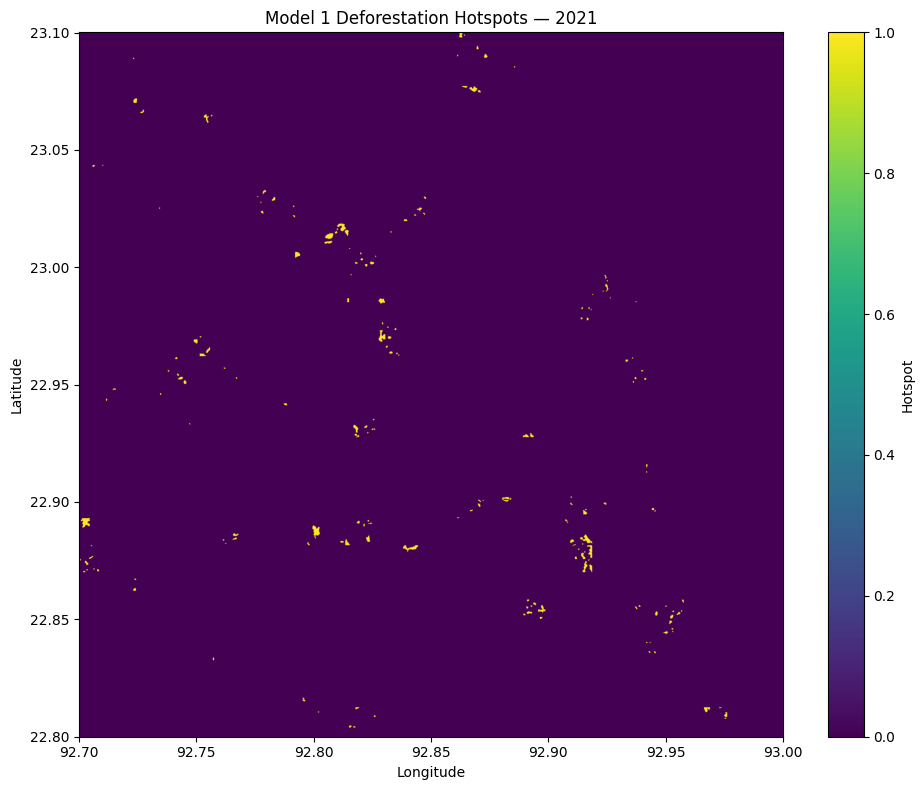

✓ Saved: /content/drive/MyDrive/Forest_AI_Project/Results/Model1/Hotspot_Maps/Model1_Hotspots_2021.png


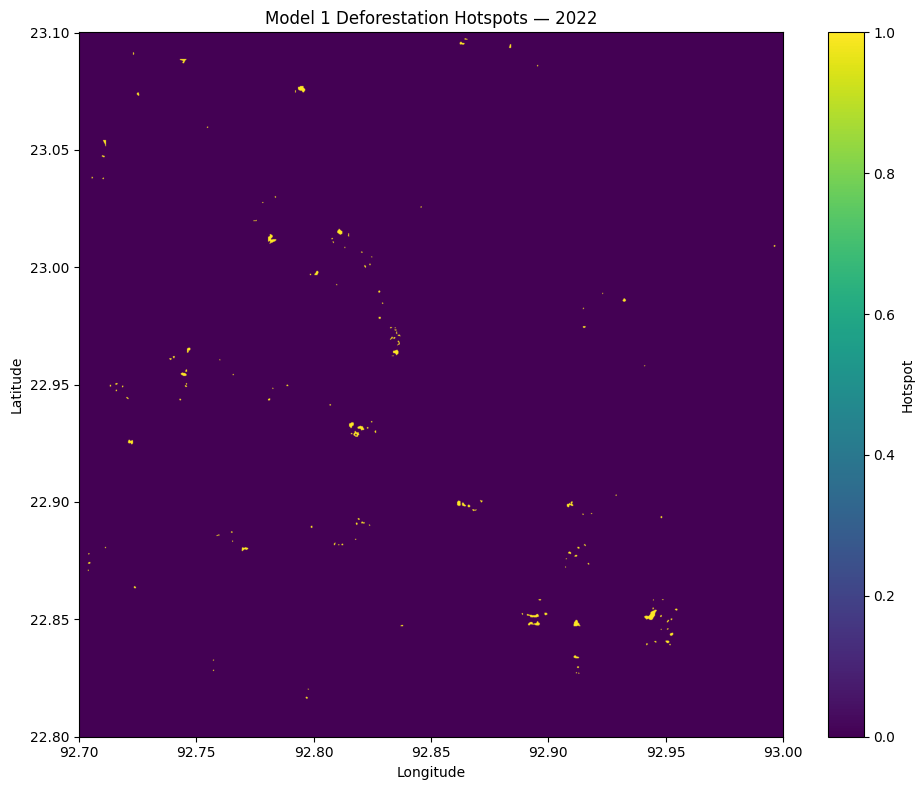

✓ Saved: /content/drive/MyDrive/Forest_AI_Project/Results/Model1/Hotspot_Maps/Model1_Hotspots_2022.png


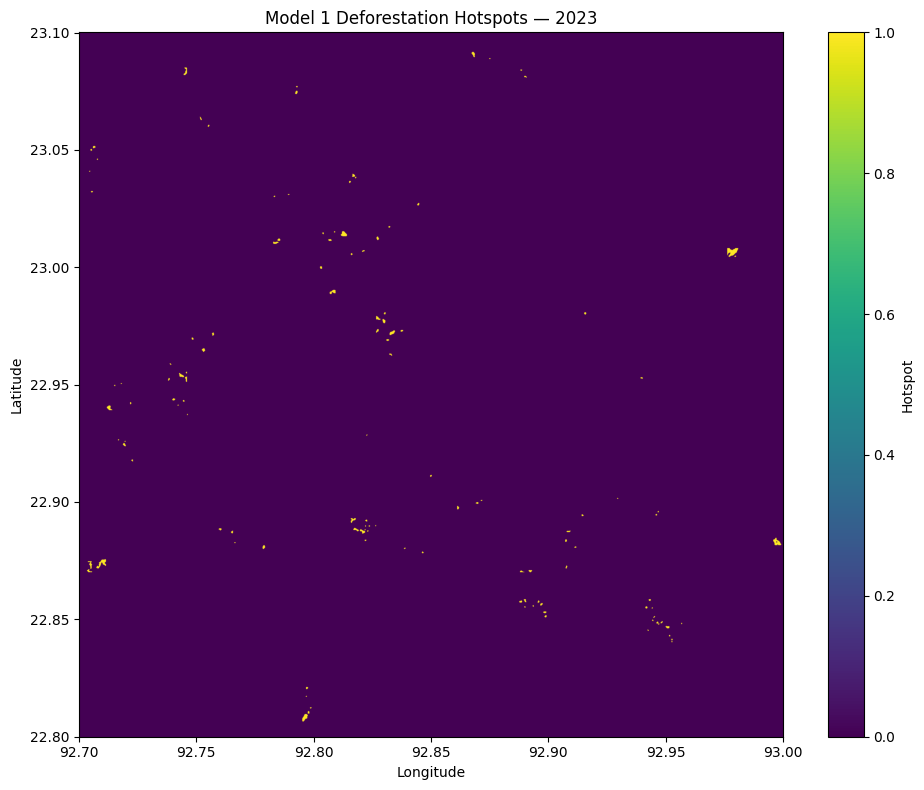

✓ Saved: /content/drive/MyDrive/Forest_AI_Project/Results/Model1/Hotspot_Maps/Model1_Hotspots_2023.png


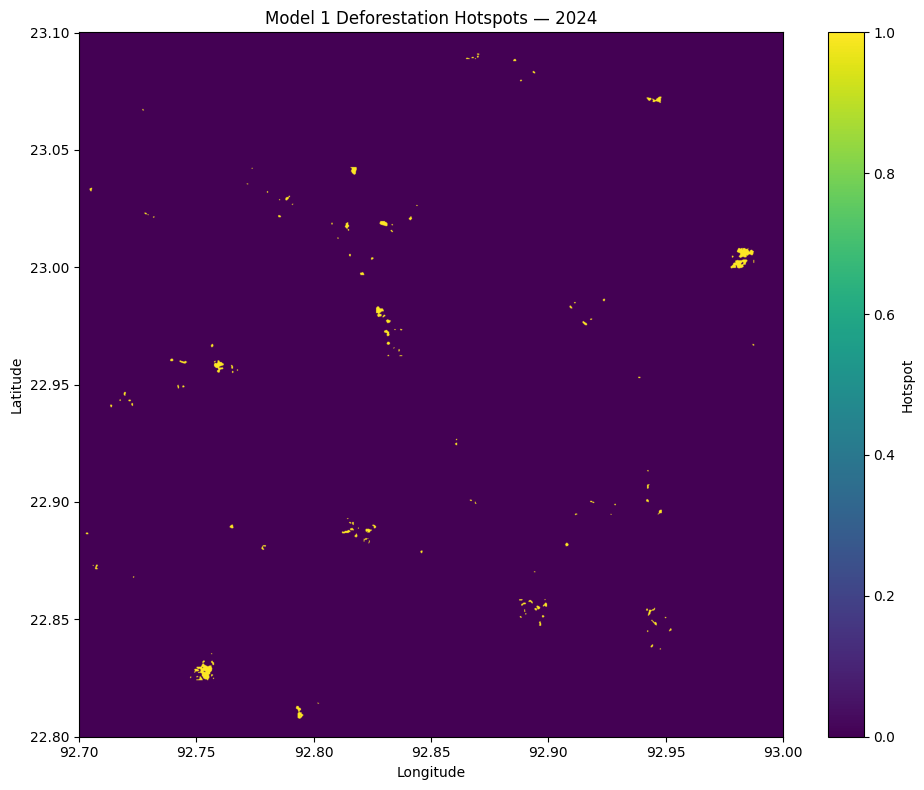

✓ Saved: /content/drive/MyDrive/Forest_AI_Project/Results/Model1/Hotspot_Maps/Model1_Hotspots_2024.png


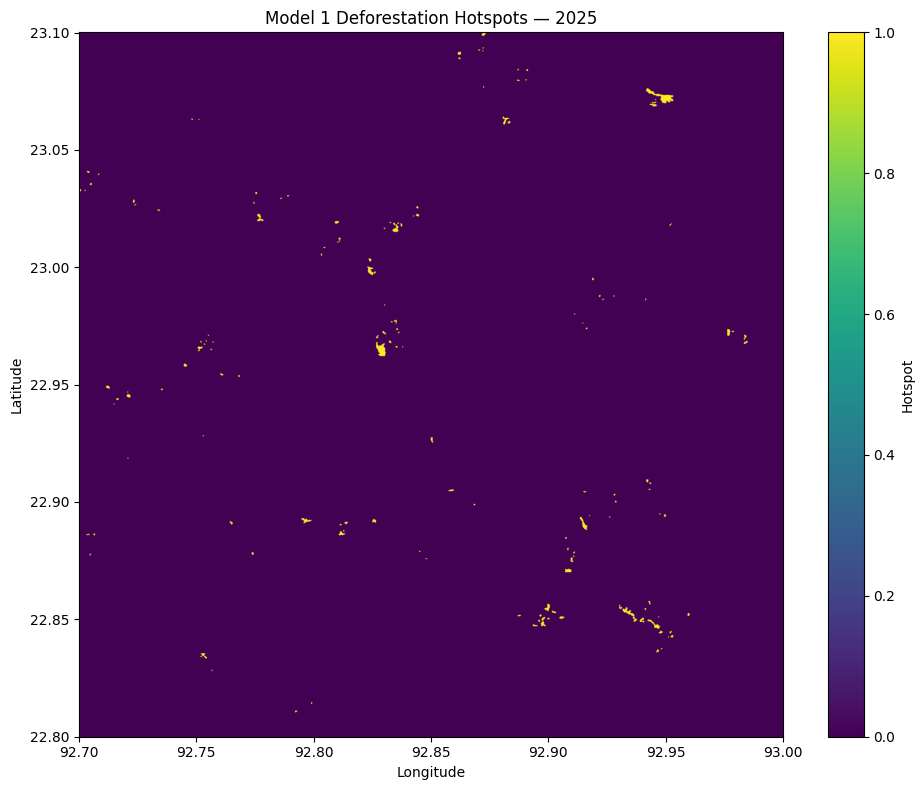

✓ Saved: /content/drive/MyDrive/Forest_AI_Project/Results/Model1/Hotspot_Maps/Model1_Hotspots_2025.png

✓ All hotspot maps generated.


In [ ]:
# ============================================================
# VISUALIZE MODEL 1 DEFORESTATION HOTSPOTS
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import rasterio

hotspot_dir = (
    "/content/drive/MyDrive/Forest_AI_Project/"
    "Results/Model1/Hotspots"
)

output_dir = (
    "/content/drive/MyDrive/Forest_AI_Project/"
    "Results/Model1/Hotspot_Maps"
)

os.makedirs(output_dir, exist_ok=True)

years = [2021, 2022, 2023, 2024, 2025]

for year in years:

    path = os.path.join(
        hotspot_dir,
        f"Model1_deforestation_hotspots_{year}.tif"
    )

    with rasterio.open(path) as src:
        hotspot = src.read(1)
        bounds = src.bounds

    plt.figure(figsize=(10, 8))

    plt.imshow(
        hotspot,
        extent=[
            bounds.left,
            bounds.right,
            bounds.bottom,
            bounds.top
        ],
        origin="upper"
    )

    plt.title(
        f"Model 1 Deforestation Hotspots — {year}"
    )

    plt.xlabel("Longitude")
    plt.ylabel("Latitude")

    plt.colorbar(
        label="Hotspot"
    )

    plt.tight_layout()

    output_path = os.path.join(
        output_dir,
        f"Model1_Hotspots_{year}.png"
    )

    plt.savefig(
        output_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    print(f"✓ Saved: {output_path}")

print()
print("✓ All hotspot maps generated.")